<div align="center">

# SP JAIN SCHOOL OF GLOBAL MANAGEMENT

## AI IN OPERATIONS
### PROBLEMS AND EXERCISES
#### Session II Lab Activity and Exercise: Retail Demand Forecasting, Naïve vs Machine Learning (MAPE & WAPE), with LLM Interpretation on Real-Time Data

---

| | |
|---|---|
| **Submitted by** | Krishna Mathur |
| **Roll Number** | AS25DXB018 |
| **Programme** | MAIB |
| **Batch** | September 2025 |
| **Subject** | AI in Operations |
| **Assignment** | Problems and Exercises |

</div>

## Table of Contents

**PART 1 — Lab Activity: Retail Demand Forecasting for a Seasonal Product (Air Coolers)**
1.1 Assignment Overview and Original Problem Statement · 1.2 Objectives and Question Checklist · 1.3 Concepts and Formulas · 1.4 Python Environment and Helper Functions · 1.5 Data Loading, Source and Inspection · 1.6 Exploratory Data Analysis · 1.7 Step 1: Baseline Naïve Forecast · 1.8 Step 2: Machine Learning Forecast (reference approach) · 1.9 Step 3: Fair Out-of-Sample Comparison · 1.10 Step 4: Operational Impact on Inventory · 1.11 Key Findings and Business Insights · 1.12 Conclusion, Limitations and References

**PART 2 — Lab Activity Exercise: Forecasting Monthly Sales for a New Beverage Product (with LLM)**
2.1 Assignment Overview and Original Problem Statement · 2.2 Question Checklist · 2.3 Python Environment · 2.4 Dataset: Source, Loading and Inspection · 2.5 Exploratory Data Analysis · 2.6 Task 1: Preprocessing · 2.7 Task 2: Model Choice · 2.8 Task 3: Train and Test · 2.9 Task 4: Next-3-Month Forecasts · 2.10 Task 5: MAPE and WAPE · 2.11 Task 6: Actual vs Predicted · 2.12 Task 7: Interpret Insights · 2.13 LLM Interpretation Based on Real-Time Data · 2.14 Recommendations, Conclusion, Limitations and References

**Overall Conclusion**

---

**How to run in Google Colab.** Choose *Runtime → Run all*. All data are downloaded live (Open-Meteo, FRED). If the internet is unavailable, the notebook falls back to the CSV files in a `data/` folder next to it, and Part 1 also has an embedded copy of its temperature data. Every library used is pre-installed in Colab. In Colab, the LLM step in Section 2.13 uses `google.colab.ai`, which needs no API key.

# PART 1 — Lab Activity: Retail Demand Forecasting for a Seasonal Product (Air Coolers)
*Session II Lab Activity, slide 57: compare a baseline Naïve forecast with a Machine Learning model using MAPE and WAPE.*

## 1.1 Assignment Overview and Original Problem Statement

The problem statement below is transcribed from the class slide (Session II, slide 57).

**Transcription of the slide**

> **Session II : Lab Activity**
>
> **Use Case: Retail Demand Forecasting for a Seasonal Product**
>
> **Scenario:** A retail company sells a seasonal product, air coolers, across 12 months. The demand fluctuates based on temperature, promotions, and seasonality. The company wants to forecast monthly demand to optimize inventory and reduce stockouts.
>
> **Objective:** Compare baseline Naïve forecast with a Machine Learning model using MAPE and WAPE metrics.

The process diagram on the slide shows the standard pipeline: **data collection → data preprocessing → clustering / classification model → model validation → forecast**. This notebook follows the same pipeline (collection, preprocessing, modelling, validation, forecast).

## 1.2 Objectives and Question Checklist

| # | Requirement from the slide | Where it is answered |
|---|---|---|
| 1 | Forecast monthly demand of air coolers for 12 months | Sections 1.7–1.9 |
| 2 | Build a **baseline Naïve** forecast | Section 1.7 |
| 3 | Build a **Machine Learning** forecast | Sections 1.8–1.9 |
| 4 | Compare both using **MAPE** | Sections 1.7–1.9 |
| 5 | Compare both using **WAPE** | Sections 1.7–1.9 |
| 6 | Reflect the drivers named in the scenario (temperature, seasonality, promotions) | Sections 1.5, 1.6, 1.9 |
| 7 | Link the forecast to inventory and stockouts | Section 1.10 |

**My approach in one line:** first reproduce the professor's reference method exactly, then test whether its conclusion still holds when the model is evaluated on months it has not seen, and finally add real temperature data, because the scenario says demand depends on temperature.

## 1.3 Concepts and Formulas

**Naïve forecast.** The forecast for next month equals the actual demand of this month. It costs nothing to build, so any "intelligent" model has to beat it to be worth using.

$$\hat{D}_{t} = D_{t-1}$$

**Random Forest regression.** An ensemble of decision trees, each trained on a bootstrap sample. The prediction is the average of the trees. With lag features $D_{t-1}, D_{t-2}$ it learns how recent demand maps to next month's demand. One property matters a lot here: a tree can only predict values it has seen during training, so it **cannot extrapolate** beyond the historical range.

**Weather-adjusted forecast (my extension).** Last month's demand corrected by the change in temperature, with $\alpha, \beta$ estimated by least squares:

$$\hat{D}_{t} = D_{t-1} + \alpha + \beta\,(T_t - T_{t-1})$$

**Error metrics**

$$\text{MAPE} = \frac{100\%}{n}\sum_{t=1}^{n}\left|\frac{D_t-\hat{D}_t}{D_t}\right| \qquad\qquad \text{WAPE} = 100\% \times \frac{\sum_{t}|D_t-\hat{D}_t|}{\sum_{t} D_t}$$

MAPE treats every month equally, so a 20-unit miss in a 90-unit month counts more than the same miss in a 220-unit month. WAPE weights errors by volume, which is closer to how an operations manager experiences the cost of a bad forecast. Lower is better for both.

## 1.4 Python Environment and Helper Functions

All libraries below are pre-installed in Google Colab, so no installation step is needed. The cell fixes a random seed so that the Random Forest results are reproducible.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# A consistent, print-friendly chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (10, 4.8), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "legend.frameon": False, "font.size": 10,
})
COLORS = {"actual": "#1f2a44", "naive": "#e07a1f", "rf": "#2a9d8f", "rf_temp": "#7b61b0",
          "weather": "#c0392b", "temp": "#d98c00"}

pd.set_option("display.precision", 2)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.1


In [2]:
def _validate(actual, predicted):
    # Convert inputs to arrays and check they can be compared
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if actual.shape != predicted.shape:
        raise ValueError(f"Shape mismatch: {actual.shape} vs {predicted.shape}")
    if np.isnan(actual).any() or np.isnan(predicted).any():
        raise ValueError("Inputs contain NaN; drop months without a forecast first.")
    if (actual == 0).any():
        raise ValueError("MAPE is undefined when an actual value is zero.")
    return actual, predicted


def mape(actual, predicted):
    # Mean Absolute Percentage Error, in %
    a, p = _validate(actual, predicted)
    return float(np.mean(np.abs((a - p) / a)) * 100)


def wape(actual, predicted):
    # Weighted Absolute Percentage Error, in %
    a, p = _validate(actual, predicted)
    return float(np.sum(np.abs(a - p)) / np.sum(a) * 100)


def score_table(actual, forecasts: dict) -> pd.DataFrame:
    # One row per model with MAPE and WAPE, sorted best first
    rows = [{"Model": name, "MAPE (%)": mape(actual, f), "WAPE (%)": wape(actual, f)}
            for name, f in forecasts.items()]
    return pd.DataFrame(rows).sort_values("WAPE (%)").reset_index(drop=True)


# Quick self-test of the metric functions on a hand-checkable example
assert abs(mape([100, 200], [90, 220]) - 10.0) < 1e-9      # (10% + 10%) / 2
assert abs(wape([100, 200], [90, 220]) - 10.0) < 1e-9      # (10 + 20) / 300
print("Metric functions validated.")

Metric functions validated.


## 1.5 Data Loading, Source and Inspection

### 1.5.1 Demand data (class dataset)
No separate data file was handed out for this lab. The demand series below is the **12-month air-cooler demand used in the professor's reference Colab notebook** for this activity (Jan–Dec 2023). That notebook itself labels these figures as *simulated monthly demand*, so they are **teaching data, not real company sales**. I keep them unchanged so that my results can be compared directly with the reference.

### 1.5.2 Temperature data (real observations)
The scenario says demand depends on temperature, but the reference notebook does not use temperature at all. To bring this driver in with **real data**, I use observed daily mean air temperature for **Dubai, UAE (25.20° N, 55.27° E)** for 2023 from the **Open-Meteo Historical Weather API** (ERA5 reanalysis), averaged to monthly values. Dubai is a natural choice: SP Jain's campus is there, and the UAE is a large air-cooling market. The cell tries the live API first, then a local CSV copy, and finally the same values embedded in the code, so it runs in Colab with or without internet.

### 1.5.3 Promotions
The scenario also mentions promotions, but no promotion calendar was provided. I do **not** invent one; this is listed as a limitation.

In [3]:
import json, urllib.request

# ---- 5.1 Class demand data (simulated teaching data from the reference notebook) ----
demand_df = pd.DataFrame({
    "Month": pd.date_range(start="2023-01-01", periods=12, freq="MS"),
    "Demand": [80, 95, 130, 160, 180, 200, 220, 210, 170, 140, 110, 90],
})

# ---- 5.2 Real monthly temperature for Dubai, 2023 ----
OPEN_METEO_URL = ("https://archive-api.open-meteo.com/v1/archive?latitude=25.2048&longitude=55.2708"
                  "&start_date=2023-01-01&end_date=2023-12-31"
                  "&daily=temperature_2m_mean,temperature_2m_max&timezone=Asia%2FDubai")
LOCAL_TEMP_CSV = "data/openmeteo_dubai_2023_monthly_temperature.csv"
# Values retrieved from the same API on 12 Nov 2026 (last-resort fallback only)
EMBEDDED_TEMP_MEAN = [19.48, 21.15, 23.73, 24.91, 30.14, 33.21, 35.53, 35.64, 34.12, 30.50, 26.61, 22.65]


def load_temperature():
    try:
        with urllib.request.urlopen(OPEN_METEO_URL, timeout=20) as resp:
            daily = pd.DataFrame(json.load(resp)["daily"])
        daily["time"] = pd.to_datetime(daily["time"])
        monthly = daily.set_index("time")["temperature_2m_mean"].resample("MS").mean()
        return monthly.round(2).values, "Open-Meteo Historical API (live request)"
    except Exception as exc:
        print("Live API unavailable:", type(exc).__name__)
    try:
        return pd.read_csv(LOCAL_TEMP_CSV)["temp_mean_c"].values, f"local file {LOCAL_TEMP_CSV}"
    except FileNotFoundError:
        return np.array(EMBEDDED_TEMP_MEAN), "embedded copy of Open-Meteo values"


temps, temp_source = load_temperature()
df = demand_df.copy()
df["Temp_C"] = temps
print("Temperature source:", temp_source)
df

Temperature source: Open-Meteo Historical API (live request)


,Month,Demand,Temp_C
0,2023-01-01,80,19.48
1,2023-02-01,95,21.15
2,2023-03-01,130,23.73
3,2023-04-01,160,24.91
4,2023-05-01,180,30.14
5,2023-06-01,200,33.21
6,2023-07-01,220,35.53
7,2023-08-01,210,35.64
8,2023-09-01,170,34.12
9,2023-10-01,140,30.50


In [4]:
# ---- Data inspection ----
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes.to_string())
print("\nMissing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate months:", df["Month"].duplicated().sum())
print("Months are consecutive:", (df["Month"].diff().dropna().dt.days.between(28, 31)).all())
df[["Demand", "Temp_C"]].describe().T

Shape (rows, columns): (12, 3)

Data types:
 Month     datetime64[us]
Demand             int64
Temp_C           float64

Missing values per column:
 Month     0
Demand    0
Temp_C    0

Duplicate months: 0
Months are consecutive: True


,count,mean,std,min,25%,50%,75%,max
Demand,12.0,148.75,48.62,80.00,106.25,150.00,185.00,220.00
Temp_C,12.0,28.14,5.78,19.48,23.46,28.38,33.44,35.64


**What the inspection tells us.** The dataset has 12 monthly rows and no missing values or duplicate months, and the months run consecutively from January to December 2023. Demand ranges from 80 to 220 units, nearly a threefold swing within one year, so this is a strongly seasonal product. Temperature runs from about 19 °C in January to about 36 °C in July–August. **Twelve observations is a very small sample.** Any model trained on it should be judged cautiously, and that point shapes the evaluation design in Section 1.9.

## 1.6 Exploratory Data Analysis

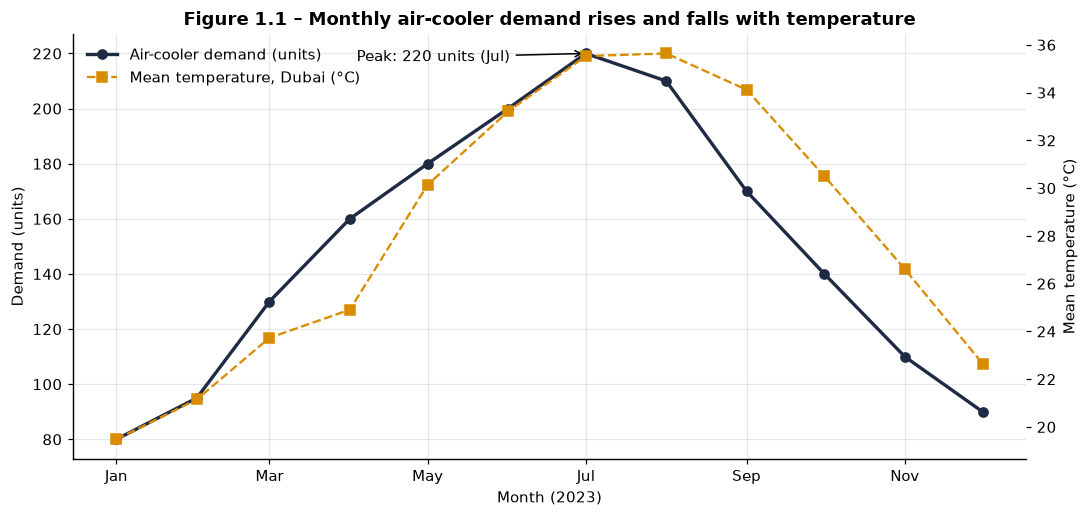

In [5]:
fig, ax1 = plt.subplots()
ax1.plot(df["Month"], df["Demand"], marker="o", color=COLORS["actual"], lw=2.2, label="Air-cooler demand (units)")
ax1.set_ylabel("Demand (units)")
ax1.set_xlabel("Month (2023)")
ax2 = ax1.twinx()
ax2.plot(df["Month"], df["Temp_C"], marker="s", ls="--", color=COLORS["temp"], label="Mean temperature, Dubai (°C)")
ax2.set_ylabel("Mean temperature (°C)")
ax2.grid(False)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
peak = df.loc[df["Demand"].idxmax()]
ax1.annotate(f"Peak: {peak.Demand} units ({peak.Month:%b})", (peak.Month, peak.Demand),
             xytext=(-150, -5), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper left")
ax1.set_title("Figure 1.1 – Monthly air-cooler demand rises and falls with temperature")
plt.tight_layout(); plt.show()

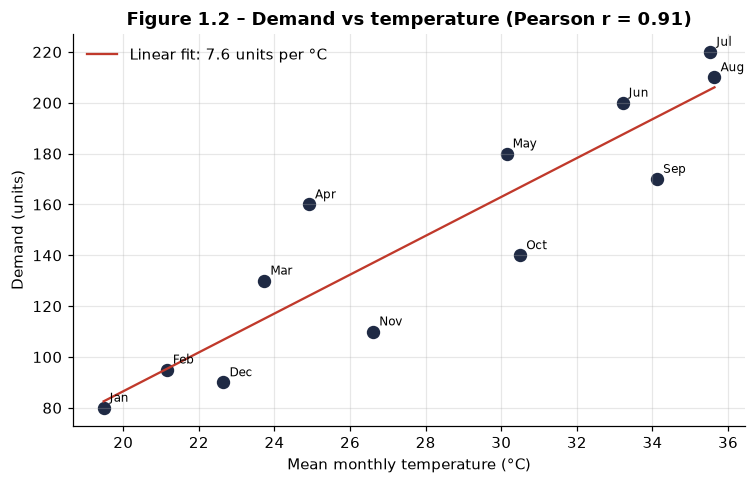

Pearson correlation demand vs temperature: 0.909
Each +1 °C in monthly mean temperature is associated with about 7.6 more units.


In [6]:
corr = df["Demand"].corr(df["Temp_C"])
slope, intercept = np.polyfit(df["Temp_C"], df["Demand"], 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["Temp_C"], df["Demand"], s=60, color=COLORS["actual"])
for _, r in df.iterrows():
    ax.annotate(r.Month.strftime("%b"), (r.Temp_C, r.Demand), xytext=(4, 4), textcoords="offset points", fontsize=8)
xs = np.linspace(df["Temp_C"].min(), df["Temp_C"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=COLORS["weather"], label=f"Linear fit: {slope:.1f} units per °C")
ax.set_xlabel("Mean monthly temperature (°C)"); ax.set_ylabel("Demand (units)")
ax.set_title(f"Figure 1.2 – Demand vs temperature (Pearson r = {corr:.2f})")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Pearson correlation demand vs temperature: {corr:.3f}")
print(f"Each +1 °C in monthly mean temperature is associated with about {slope:.1f} more units.")

**Interpretation of Figures 1.1 and 1.2.** Demand climbs steadily from January to a peak of 220 units in July and then falls back to 90 units by December. Temperature follows almost the same arc, and the correlation is very strong (r ≈ 0.91). Two details matter for forecasting:

* **Demand leads temperature at the turning point.** Temperature stays at its maximum in August, but demand has already started to fall. Customers who needed a cooler have bought one by mid-summer, so the market saturates before the heat ends. A pure "temperature → demand" model will over-forecast August and September.
* **The autumn months are labelled in Figure 1.2 and sit below the trend line.** At the same temperature, autumn demand is lower than spring demand. This is classic seasonal-goods behaviour: pre-season buying is stronger than post-season buying.

Both effects suggest combining **recent demand** with **the change in temperature**, which is exactly the weather-adjusted model tested in Section 1.9.

## 1.7 Step 1: Baseline Naïve Forecast

$\hat{D}_t = D_{t-1}$. January has no previous month, so it has no forecast and is excluded from scoring.

In [7]:
df["Naive_Forecast"] = df["Demand"].shift(1)
naive_eval = df.dropna(subset=["Naive_Forecast"])

naive_mape = mape(naive_eval["Demand"], naive_eval["Naive_Forecast"])
naive_wape = wape(naive_eval["Demand"], naive_eval["Naive_Forecast"])

work = naive_eval[["Month", "Demand", "Naive_Forecast"]].copy()
work["Abs_Error"] = (work["Demand"] - work["Naive_Forecast"]).abs()
work["Abs_%_Error"] = work["Abs_Error"] / work["Demand"] * 100
print(work.assign(Month=work.Month.dt.strftime("%b")).to_string(index=False))
print(f"\nSum of absolute errors = {work.Abs_Error.sum():.0f}; sum of demand = {work.Demand.sum():.0f}")
print(f"Naïve MAPE (Feb–Dec) = {naive_mape:.2f}%   |   Naïve WAPE (Feb–Dec) = {naive_wape:.2f}%")

Month  Demand  Naive_Forecast  Abs_Error  Abs_%_Error
  Feb      95            80.0       15.0        15.79
  Mar     130            95.0       35.0        26.92
  Apr     160           130.0       30.0        18.75
  May     180           160.0       20.0        11.11
  Jun     200           180.0       20.0        10.00
  Jul     220           200.0       20.0         9.09
  Aug     210           220.0       10.0         4.76
  Sep     170           210.0       40.0        23.53
  Oct     140           170.0       30.0        21.43
  Nov     110           140.0       30.0        27.27
  Dec      90           110.0       20.0        22.22

Sum of absolute errors = 270; sum of demand = 1705
Naïve MAPE (Feb–Dec) = 17.35%   |   Naïve WAPE (Feb–Dec) = 15.84%


**Working.** WAPE = 270 / 1,705 = 15.84%. MAPE is the average of the eleven monthly percentage errors, 17.35%. The naïve forecast is always exactly one month late: it under-forecasts every month while demand rises (Feb–Jul) and over-forecasts every month while demand falls (Aug–Dec). For inventory, this means **stockouts in the build-up season and excess stock at the end of the season**. These are the two problems the company wants to reduce.

## 1.8 Step 2: Machine Learning Forecast (Random Forest, reference approach)

Here I reproduce the method from the professor's reference notebook: a Random Forest with two lag features ($D_{t-1}$, $D_{t-2}$), **trained and scored on the same months** (March–December, because two lags are needed).

In [8]:
df["Lag1"] = df["Demand"].shift(1)
df["Lag2"] = df["Demand"].shift(2)
ml_df = df.dropna(subset=["Lag1", "Lag2"]).copy()

rf_insample = RandomForestRegressor(random_state=RANDOM_STATE)
rf_insample.fit(ml_df[["Lag1", "Lag2"]], ml_df["Demand"])
ml_df["RF_InSample"] = rf_insample.predict(ml_df[["Lag1", "Lag2"]])

insample_scores = score_table(ml_df["Demand"], {
    "Naïve (Mar–Dec)": ml_df["Naive_Forecast"],
    "Random Forest – in-sample (Mar–Dec)": ml_df["RF_InSample"],
})
insample_scores

,Model,MAPE (%),WAPE (%)
0,Random Forest – in-sample (Mar–Dec),8.51,7.76
1,Naïve (Mar–Dec),17.51,15.84


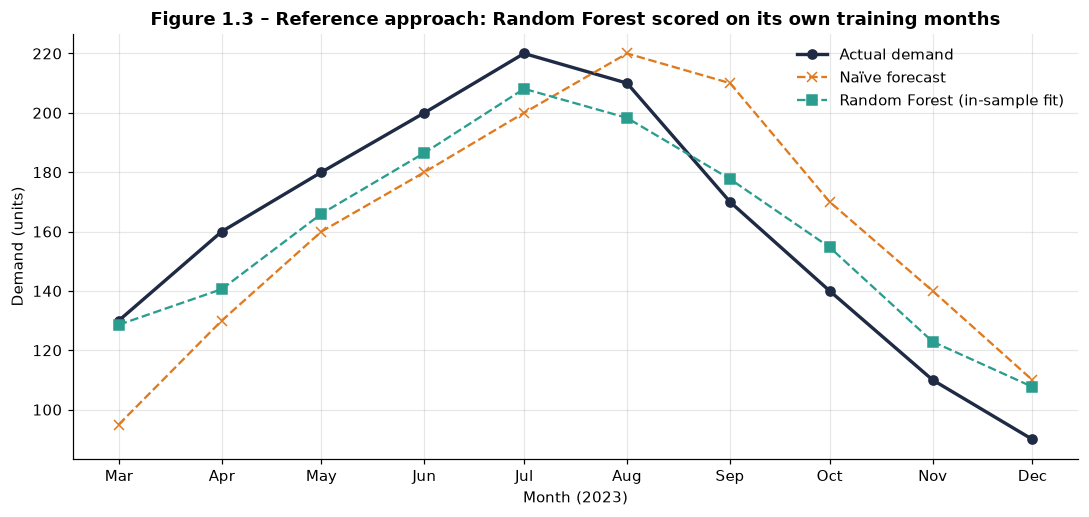

In [9]:
fig, ax = plt.subplots()
ax.plot(ml_df["Month"], ml_df["Demand"], marker="o", color=COLORS["actual"], lw=2.2, label="Actual demand")
ax.plot(ml_df["Month"], ml_df["Naive_Forecast"], marker="x", ls="--", color=COLORS["naive"], label="Naïve forecast")
ax.plot(ml_df["Month"], ml_df["RF_InSample"], marker="s", ls="--", color=COLORS["rf"], label="Random Forest (in-sample fit)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlabel("Month (2023)"); ax.set_ylabel("Demand (units)")
ax.set_title("Figure 1.3 – Reference approach: Random Forest scored on its own training months")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** On this measure the Random Forest roughly halves the naïve error (about 8.5% vs 17.5% MAPE), which matches the conclusion of the reference notebook. However, the model is being marked on the **same ten months it learned from**. With 100 trees and only ten rows, a Random Forest can nearly memorise the data, so this is a measure of *fit*, not of *forecasting ability*. A manager using the model in January 2024 would not know the answers in advance. The next section therefore tests every model only on months that lie **after** its training data.

## 1.9 Step 3: Fair Out-of-Sample Comparison (walk-forward validation)

**Design.** For each month from **July to December** (the peak and decline, the hardest part of the season), every model is retrained using only the months before it and then forecasts that single month. This is called *expanding-window* or *walk-forward* validation and mimics how the model would be used in practice: each month you refit with the latest data and forecast the next month.

Models compared:
1. **Naïve:** $\hat D_t = D_{t-1}$
2. **Random Forest (lags):** the reference model, now evaluated honestly
3. **Random Forest (lags + temperature):** adds the real temperature driver
4. **Weather-adjusted regression:** $\hat D_t = D_{t-1} + \alpha + \beta (T_t - T_{t-1})$

*Assumption:* the temperature of the month being forecast is treated as known. In practice it would come from a monthly weather outlook. Seasonal temperature in Dubai is highly regular, so this is a realistic assumption, but it is stated openly.

In [10]:
df["dDemand"] = df["Demand"].diff()
df["dTemp"] = df["Temp_C"].diff()

TEST_IDX = list(range(6, 12))          # Jul (index 6) to Dec (index 11)
preds = {"Naïve": [], "Random Forest (lags)": [], "Random Forest (lags + temp)": [], "Weather-adjusted regression": []}

for i in TEST_IDX:
    train = df.iloc[2:i]                # rows with both lags available, strictly before month i
    test = df.iloc[[i]]

    preds["Naïve"].append(test["Naive_Forecast"].item())

    rf_lag = RandomForestRegressor(random_state=RANDOM_STATE).fit(train[["Lag1", "Lag2"]], train["Demand"])
    preds["Random Forest (lags)"].append(rf_lag.predict(test[["Lag1", "Lag2"]])[0])

    rf_tmp = RandomForestRegressor(random_state=RANDOM_STATE).fit(train[["Lag1", "Lag2", "Temp_C"]], train["Demand"])
    preds["Random Forest (lags + temp)"].append(rf_tmp.predict(test[["Lag1", "Lag2", "Temp_C"]])[0])

    diff_train = df.iloc[1:i]           # month-on-month changes observed so far
    reg = LinearRegression().fit(diff_train[["dTemp"]], diff_train["dDemand"])
    preds["Weather-adjusted regression"].append(test["Lag1"].item() + reg.predict(test[["dTemp"]])[0])

wf = df.iloc[TEST_IDX][["Month", "Demand"]].copy()
for name, p in preds.items():
    wf[name] = np.round(p, 1)
print("Walk-forward one-step-ahead forecasts (units):")
print(wf.assign(Month=wf.Month.dt.strftime("%b")).to_string(index=False))

final_reg = LinearRegression().fit(df.iloc[1:][["dTemp"]], df.iloc[1:]["dDemand"])
print(f"\nWeather-adjusted model fitted on all 2023 data: dDemand = {final_reg.intercept_:.2f} + {final_reg.coef_[0]:.2f} × dTemp")

Walk-forward one-step-ahead forecasts (units):
Month  Demand  Naïve  Random Forest (lags)  Random Forest (lags + temp)  Weather-adjusted regression
  Jul     220  200.0                 192.8                        192.8                        224.5
  Aug     210  220.0                 211.0                        211.0                        246.2
  Sep     170  210.0                 214.2                        212.0                        213.5
  Oct     140  170.0                 192.8                        186.1                        131.9
  Nov     110  140.0                 172.9                        161.9                        104.0
  Dec      90  110.0                 139.1                        143.4                         75.7

Weather-adjusted model fitted on all 2023 data: dDemand = -1.21 + 7.37 × dTemp


In [11]:
oos_scores = score_table(wf["Demand"], {k: wf[k] for k in preds})
naive_row = oos_scores.set_index("Model").loc["Naïve"]
oos_scores["WAPE change vs Naïve (pp)"] = oos_scores["WAPE (%)"] - naive_row["WAPE (%)"]
oos_scores

,Model,MAPE (%),WAPE (%),WAPE change vs Naïve (pp)
0,Weather-adjusted regression,12.00,11.98,-3.98
1,Naïve,18.05,15.96,0.00
2,Random Forest (lags + temp),29.50,23.57,7.62
3,Random Forest (lags),31.38,25.23,9.28


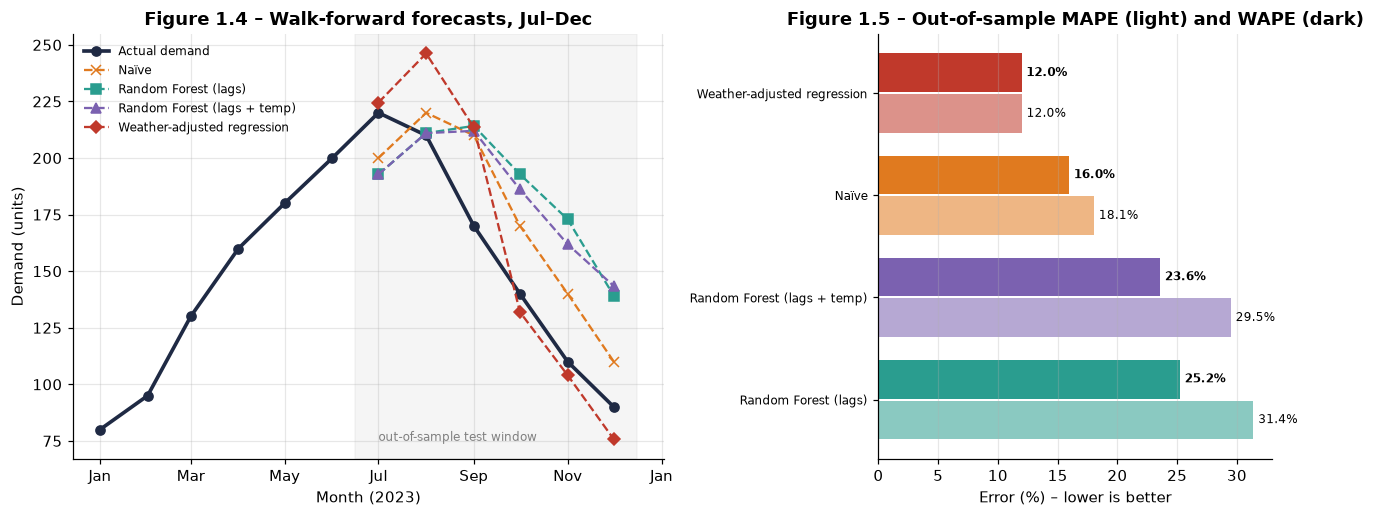

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
palette = [COLORS["naive"], COLORS["rf"], COLORS["rf_temp"], COLORS["weather"]]
markers = ["x", "s", "^", "D"]

ax = axes[0]
ax.plot(df["Month"], df["Demand"], marker="o", color=COLORS["actual"], lw=2.4, label="Actual demand")
for (name, col, mk) in zip(preds, palette, markers):
    ax.plot(wf["Month"], wf[name], marker=mk, ls="--", color=col, label=name)
ax.axvspan(df["Month"].iloc[6] - pd.Timedelta(days=15), df["Month"].iloc[11] + pd.Timedelta(days=15), color="grey", alpha=0.08)
ax.text(df["Month"].iloc[6], 75, "out-of-sample test window", fontsize=8, color="grey")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlabel("Month (2023)"); ax.set_ylabel("Demand (units)")
ax.set_title("Figure 1.4 – Walk-forward forecasts, Jul–Dec")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
order = oos_scores.sort_values("WAPE (%)", ascending=False)
col_map = dict(zip(preds, palette))
y = np.arange(len(order))
ax.barh(y - 0.2, order["MAPE (%)"], height=0.38, color=[col_map[m] for m in order["Model"]], alpha=0.55, label="MAPE")
ax.barh(y + 0.2, order["WAPE (%)"], height=0.38, color=[col_map[m] for m in order["Model"]], label="WAPE")
for yi, (mp, wp) in enumerate(zip(order["MAPE (%)"], order["WAPE (%)"])):
    ax.text(mp + 0.4, yi - 0.2, f"{mp:.1f}%", va="center", fontsize=8)
    ax.text(wp + 0.4, yi + 0.2, f"{wp:.1f}%", va="center", fontsize=8, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(order["Model"], fontsize=8)
ax.set_xlabel("Error (%) – lower is better")
ax.set_title("Figure 1.5 – Out-of-sample MAPE (light) and WAPE (dark)")
ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

**Interpretation of Figures 1.4 and 1.5.**

* **The Random Forest result reverses.** Once it has to forecast unseen months, the reference Random Forest has the *highest* error of all models, clearly worse than naïve. The reason is visible in Figure 1.4: after the July peak the trees keep predicting values close to the high summer levels they were trained on (about 190–215 units) while actual demand drops to 170, 140 and 110. Trees cannot extrapolate below the range of their training targets, and with only four to nine training rows they have almost nothing to learn from.
* **Adding temperature to the Random Forest helps only slightly**, because the algorithm's structural limits remain.
* **The weather-adjusted regression is the best model on both metrics.** It is the only model that "turns" with the season: when September and October cool down, it immediately predicts a drop. Its one large miss is August (246 forecast vs 210 actual): at that point it has only seen months in which demand rose, so it still expects growth. As soon as the September decline enters its training data it adapts, and over the six months its errors are clearly smaller than naïve (WAPE 12.0% vs 16.0%).
* **The lesson for model selection:** a model with the right *driver* (temperature) and the right *structure* (forecast the change, not the level) beats a more complex algorithm fed only with lags. "Machine learning" does not automatically mean better forecasts, especially with 12 data points.

## 1.10 Step 4: Operational Impact on Inventory

If the company stocks each month exactly what the forecast says, an **under-forecast** becomes a **stockout** (lost sales) and an **over-forecast** becomes **excess inventory** (holding cost, end-of-season markdowns). The table translates the forecast errors over July–December into these two operational quantities.

,Model,Stockout units (under-forecast),Excess units (over-forecast),Total units mis-planned,Share of Jul–Dec demand (%)
0,Weather-adjusted regression,28.4,84.2,112.6,12.0
1,Naïve,20.0,130.0,150.0,16.0
2,Random Forest (lags + temp),27.2,194.4,221.6,23.6
3,Random Forest (lags),27.2,210.0,237.2,25.2


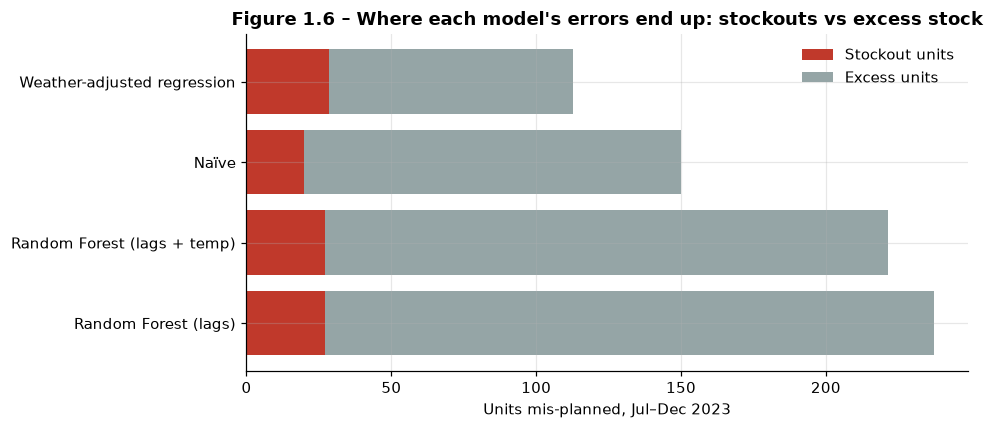

In [13]:
impact_rows = []
for name in preds:
    err = wf[name] - wf["Demand"]                 # positive = over-forecast
    impact_rows.append({
        "Model": name,
        "Stockout units (under-forecast)": float(-err[err < 0].sum()),
        "Excess units (over-forecast)": float(err[err > 0].sum()),
        "Total units mis-planned": float(err.abs().sum()),
    })
impact = pd.DataFrame(impact_rows).sort_values("Total units mis-planned").reset_index(drop=True)
impact["Share of Jul–Dec demand (%)"] = impact["Total units mis-planned"] / wf["Demand"].sum() * 100
display(impact.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(impact["Model"], impact["Stockout units (under-forecast)"], color="#c0392b", label="Stockout units")
ax.barh(impact["Model"], impact["Excess units (over-forecast)"], left=impact["Stockout units (under-forecast)"],
        color="#95a5a6", label="Excess units")
ax.invert_yaxis(); ax.set_xlabel("Units mis-planned, Jul–Dec 2023")
ax.set_title("Figure 1.6 – Where each model's errors end up: stockouts vs excess stock")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** Over the six critical months (total demand of 940 units), the naïve plan is wrong by 150 units, and **almost all of that is excess stock** because naïve keeps ordering for last month's higher demand as the season declines. The Random Forest plans are worse still, ending the season with roughly 195–210 surplus coolers that would have to be marked down or carried into next year. The weather-adjusted model cuts total mis-planned units by about a quarter (113 vs 150) and reduces excess stock from 130 to 84 units, at the cost of about 8 more units of stockout. That trade-off is attractive for a product whose leftover stock loses most of its value after the season.

## 1.11 Key Findings and Business Insights

**Key findings**
1. **Baseline:** the naïve forecast has MAPE 17.35% and WAPE 15.84% over February–December. It lags the season by one month in both directions.
2. **Reference ML result:** the in-sample Random Forest appears to beat naïve (≈8.5% vs 17.5% MAPE), but this is a fitting score, not a forecasting score.
3. **Honest result:** in walk-forward validation (Jul–Dec) the lag-only Random Forest is the **worst** model, because it cannot follow the post-peak decline.
4. **Best model:** a simple weather-adjusted regression that uses real temperature data gives the lowest MAPE and WAPE out of sample and the fewest mis-planned units.
5. **Demand saturates before temperature peaks:** sales turn down in August even though August is as hot as July.

**Recommendations for the retailer**
* **Use temperature as a leading input** in the demand plan, for example from a 30-day weather outlook, rather than relying only on last month's sales.
* **Front-load inventory in March–June** and start reducing replenishment orders **as soon as July demand stops growing**, not when temperatures fall. The data show that the end-of-season surplus is the main cost of a lagging forecast.
* **Record promotions** (dates, depth of discount) from now on so that their effect can be separated from temperature next season.
* **Collect at least two to three seasons of data** before relying on tree-based ML models. With 12 points, simple, well-specified models are safer.
* **Always validate on unseen periods** (walk-forward). In-sample accuracy can recommend the wrong model.

## 1.12 Conclusion, Limitations and References

### Conclusion
The lab asked for a comparison between a naïve forecast and a machine learning model using MAPE and WAPE. Using the reference method, the Random Forest looks clearly better. When it is evaluated properly on months it has not seen, it is worse than naïve, because one year of data is too little for a tree ensemble and trees cannot extrapolate into the declining season. Adding a real driver, temperature, in a simple and interpretable model gives the most accurate forecast and the smallest stockout and overstock exposure. For an operations team, choosing the **right inputs and validation method** matters more than choosing the most sophisticated algorithm.

### Limitations
* The demand series is the 12-month **simulated teaching dataset** from the reference notebook, not observed company sales. Results show the method, not a specific retailer's performance.
* Only six out-of-sample months are scored, so the metric differences have wide uncertainty.
* The forecast-month temperature is assumed known (from a weather outlook). Real forecasts would add some error.
* Promotions are named in the scenario but no promotion data were provided, so their effect is not modelled.
* Dubai temperature is used as the climate driver. A retailer in another region should use its own local weather.

### References
1. Course material: Session II Lab Activity slide 57, *AI in Operations* lecture notes, SP Jain School of Global Management.
2. Professor's reference Google Colab notebook for the lab (air-cooler demand data, Naïve vs Random Forest, MAPE/WAPE).
3. Open-Meteo (2026). *Historical Weather API* (ERA5-based reanalysis). https://open-meteo.com/en/docs/historical-weather-api. Daily mean 2 m temperature, Dubai, 2023.
4. Hyndman, R.J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed., OTexts. https://otexts.com/fpp3/ (naïve benchmarks, time-series cross-validation).
5. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
6. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

In [14]:
# Compact machine-readable summary of the results in this notebook
summary = {
    "naive_feb_dec": {"MAPE": round(naive_mape, 2), "WAPE": round(naive_wape, 2)},
    "in_sample_mar_dec": insample_scores.set_index("Model").round(2).to_dict(orient="index"),
    "walk_forward_jul_dec": oos_scores.set_index("Model")[["MAPE (%)", "WAPE (%)"]].round(2).to_dict(orient="index"),
    "units_misplanned_jul_dec": impact.set_index("Model")["Total units mis-planned"].round(1).to_dict(),
    "demand_temp_correlation": round(corr, 3),
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "naive_feb_dec": {
    "MAPE": 17.35,
    "WAPE": 15.84
  },
  "in_sample_mar_dec": {
    "Random Forest – in-sample (Mar–Dec)": {
      "MAPE (%)": 8.51,
      "WAPE (%)": 7.76
    },
    "Naïve (Mar–Dec)": {
      "MAPE (%)": 17.51,
      "WAPE (%)": 15.84
    }
  },
  "walk_forward_jul_dec": {
    "Weather-adjusted regression": {
      "MAPE (%)": 12.0,
      "WAPE (%)": 11.98
    },
    "Naïve": {
      "MAPE (%)": 18.05,
      "WAPE (%)": 15.96
    },
    "Random Forest (lags + temp)": {
      "MAPE (%)": 29.5,
      "WAPE (%)": 23.57
    },
    "Random Forest (lags)": {
      "MAPE (%)": 31.38,
      "WAPE (%)": 25.23
    }
  },
  "units_misplanned_jul_dec": {
    "Weather-adjusted regression": 112.6,
    "Naïve": 150.0,
    "Random Forest (lags + temp)": 221.6,
    "Random Forest (lags)": 237.2
  },
  "demand_temp_correlation": 0.909
}


---
# PART 2 — Lab Activity Exercise: Forecasting Monthly Sales for a New Beverage Product
*Session II Lab Activity – Exercise: Tasks 1–7, plus an LLM interpretation based on real-time data.*

Part 2 is self-contained: it re-imports its libraries and redefines its helper functions, so it can also be run on its own.

## 2.1 Assignment Overview and Original Problem Statement

The problem statement below is transcribed from the two class exercise slides (use case and tasks).

**Transcription: Session II: Lab Activity – Exercise**

> **Use Case: Forecasting Monthly Sales for a New Beverage Product**
>
> **Scenario:** A beverage company has launched a new flavored water product in regional markets. They've collected monthly sales data for the first year and want to forecast demand for the upcoming months to optimize production and distribution. Students are tasked with applying a chosen forecasting model (e.g., Naive, ARIMA, Random Forest, XGBoost) to this dataset and evaluating its performance using MAPE and WAPE.
>
> **Tasks**
> 1. Preprocess the dataset: Create lag features or seasonal indicators if needed.
> 2. Choose a forecasting model: Naïve, ARIMA, or ML-based (e.g., Random Forest).
> 3. Train and test the model: Use appropriate train-test split.
> 4. Generate forecasts: Predict next 3 months.
> 5. Evaluate performance: Calculate MAPE and WAPE.
> 6. Visualize results: Plot actual vs predicted sales.
> 7. Interpret insights:
>    - How well did the model capture seasonality or trends?
>    - Which model performed best and why?
>    - What recommendations would you give the company?
>
> **Must add LLM to create an interpretation based on real-time data.** *(Refer to Day 10 of RDMU for LLM integration.)*
>
> **Expected Learning Outcomes:** understand model selection and feature engineering; gain hands-on experience with forecasting metrics; learn to interpret and communicate model results using LLM; appreciate the business impact of accurate forecasting.

## 2.2 Question Checklist

| Requirement | Section | Delivered as |
|---|---|---|
| Task 1: lag features / seasonal indicators | 2.6 | Lags 1, 2, 3, 12; rolling means; cyclical month encoding |
| Task 2: choose Naïve, ARIMA, ML models | 2.7 | Naïve, Seasonal Naïve, SARIMA (AIC grid search), Holt-Winters, Random Forest, XGBoost |
| Task 3: appropriate train-test split | 2.8 | Chronological split, last 12 months held out, plus rolling-origin backtest |
| Task 4: forecast the next 3 months | 2.9 | All models refitted on full data, with SARIMA prediction intervals |
| Task 5: MAPE and WAPE | 2.10 | Metric table and 3-month-ahead backtest |
| Task 6: plot actual vs predicted | 2.11 | Test-period, error and forward-forecast charts |
| Task 7: three interpretation questions | 2.12 | Evidence-based answers, plus a "first-year-only" analysis |
| LLM interpretation on real-time data | 2.13 | Live FRED data and live weather forecast passed to an LLM |

**Note on the "first year of data".** No dataset was handed out with the slide. Sections 2.4 and 2.12.3 explain how I handled this honestly with real public data, and how the method transfers to a new product with only 12 months of history.

## 2.3 Python Environment

Everything used here is pre-installed in Google Colab (`pandas`, `numpy`, `matplotlib`, `scikit-learn`, `statsmodels`, `xgboost`). The installation line runs only if a package is missing.

In [15]:
import importlib, subprocess, sys
for pkg in ["statsmodels", "xgboost", "sklearn"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "scikit-learn" if pkg == "sklearn" else pkg])

import io, os, json, itertools, warnings, urllib.request
from datetime import datetime, timezone, date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({
    "figure.figsize": (11, 4.8), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "legend.frameon": False, "font.size": 10,
})
MODEL_COLORS = {"Actual": "#1f2a44", "Naïve": "#e07a1f", "Seasonal Naïve": "#b08d57", "SARIMA": "#c0392b",
                "Holt-Winters": "#2e86c1", "Random Forest": "#2a9d8f", "XGBoost": "#7b61b0"}
import sklearn, statsmodels, xgboost
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__,
      "| xgboost", xgboost.__version__)

pandas 3.1.1 | scikit-learn 1.9.1 | statsmodels 0.15.0 | xgboost 3.4.1


In [16]:
def _check(actual, predicted):
    a = np.asarray(actual, dtype=float); p = np.asarray(predicted, dtype=float)
    if a.shape != p.shape:
        raise ValueError(f"Shape mismatch {a.shape} vs {p.shape}")
    if np.isnan(a).any() or np.isnan(p).any():
        raise ValueError("NaN values found in actuals or forecasts")
    if (a == 0).any():
        raise ValueError("MAPE undefined for zero actuals")
    return a, p

def mape(actual, predicted):
    a, p = _check(actual, predicted); return float(np.mean(np.abs((a - p) / a)) * 100)

def wape(actual, predicted):
    a, p = _check(actual, predicted); return float(np.abs(a - p).sum() / a.sum() * 100)

def rmse(actual, predicted):
    a, p = _check(actual, predicted); return float(np.sqrt(np.mean((a - p) ** 2)))

def bias_pct(actual, predicted):
    # Positive = over-forecasting on average (too much stock), negative = under-forecasting (stockouts)
    a, p = _check(actual, predicted); return float((p - a).sum() / a.sum() * 100)

assert abs(mape([100, 200], [90, 220]) - 10) < 1e-9 and abs(wape([100, 200], [90, 220]) - 10) < 1e-9
print("Metric functions validated.")

Metric functions validated.


## 2.4 Dataset: Source, Loading and Inspection

### 2.4.1 Why this dataset
The slide describes a company's first-year sales, but **no data file was provided**, and company-level sales of a specific flavored-water brand are not publicly available. Rather than inventing numbers, I use the closest **real, official, monthly** series for this product category:

| Item | Detail |
|---|---|
| Series | *Industrial Production: Manufacturing: Non-Durable Goods: Soft Drink and Ice* (FRED code **IPN31211N**) |
| Publisher | Board of Governors of the Federal Reserve System, distributed by FRED, Federal Reserve Bank of St. Louis |
| Coverage | NAICS 31211, which includes bottled water (312112) and soft drinks: the industry that produces flavored water |
| Unit | Index, 2017 = 100, **not seasonally adjusted**, so the real seasonality is preserved |
| Frequency | Monthly; this notebook uses January 2012 to the latest available month |
| URL | https://fred.stlouisfed.org/series/IPN31211N |

Production volume is the operational quantity a beverage company has to plan. Because MAPE and WAPE are **scale-free**, results expressed as an index carry over directly to a brand's unit sales. Section 2.12.3 then simulates the company's actual situation of only having **one year** of history.

### 2.4.2 Loading (real-time)
The cell downloads the series **live** from FRED every time it runs, so the analysis always uses the latest data release. If the internet is unavailable, it falls back to the copy in `data/`.

In [17]:
FRED_SERIES = "IPN31211N"
FRED_URL = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={FRED_SERIES}"
LOCAL_CSV = "data/fred_IPN31211N_soft_drink_production.csv"

def load_fred():
    try:
        with urllib.request.urlopen(FRED_URL, timeout=30) as resp:
            raw = pd.read_csv(io.StringIO(resp.read().decode()))
        return raw, "FRED live download"
    except Exception as exc:
        print("Live FRED download failed:", type(exc).__name__, "- using local copy")
        return pd.read_csv(LOCAL_CSV), f"local file {LOCAL_CSV}"

raw, data_source = load_fred()
retrieved_at = datetime.now(timezone.utc)
date_col = "observation_date" if "observation_date" in raw.columns else raw.columns[0]
raw[date_col] = pd.to_datetime(raw[date_col])
raw[FRED_SERIES] = pd.to_numeric(raw[FRED_SERIES], errors="coerce")

print("Source:", data_source, "| retrieved:", retrieved_at.strftime("%Y-%m-%d %H:%M UTC"))
print("Full history:", raw[date_col].min().date(), "to", raw[date_col].max().date(), "|", len(raw), "rows")
raw.tail()

Source: FRED live download | retrieved: 2026-11-12 09:37 UTC
Full history: 1972-01-01 to 2026-09-01 | 657 rows


,observation_date,IPN31211N
652,2026-05-01,94.49
653,2026-06-01,95.87
654,2026-07-01,98.39
655,2026-08-01,96.31
656,2026-09-01,95.95


In [18]:
# Keep January 2012 onwards: about 15 years, enough for SARIMA/ML, recent enough to reflect today's market
sales = (raw.rename(columns={date_col: "month", FRED_SERIES: "sales_index"})
            .set_index("month")["sales_index"].asfreq("MS"))
sales = sales.loc["2012-01-01":]

print("Rows:", len(sales), "| from", sales.index.min().date(), "to", sales.index.max().date())
print("dtype:", sales.dtype)
print("Missing values:", int(sales.isna().sum()))
print("Duplicate dates:", int(sales.index.duplicated().sum()))
print("Regular monthly frequency:", sales.index.freqstr)
yoy = sales.pct_change(12) * 100
print("\nLargest year-on-year moves (possible shocks):")
print(yoy.abs().sort_values(ascending=False).head(4).round(1).to_string())
sales.describe().to_frame().T.round(2)

Rows: 177 | from 2012-01-01 to 2026-09-01
dtype: float64
Missing values: 0
Duplicate dates: 0
Regular monthly frequency: MS

Largest year-on-year moves (possible shocks):
month
2025-07-01    15.6
2025-06-01    13.8
2025-08-01    12.3
2016-09-01    12.2


,count,mean,std,min,25%,50%,75%,max
sales_index,177.0,101.84,7.53,88.86,95.74,99.99,107.9,119.42


**Data quality.** The series is complete: no missing values, no duplicate months and a regular monthly frequency, so no imputation is needed. The largest year-on-year moves are in **summer 2025 (about −14% to −16%)**. After an exceptionally strong summer 2024, production fell sharply in late 2024 and has stayed at the lower level since. This is a real market event, so I keep it rather than "cleaning" it away. It matters for the evaluation: any model that simply copies last year (Seasonal Naïve) will be pulled off course by it.

## 2.5 Exploratory Data Analysis

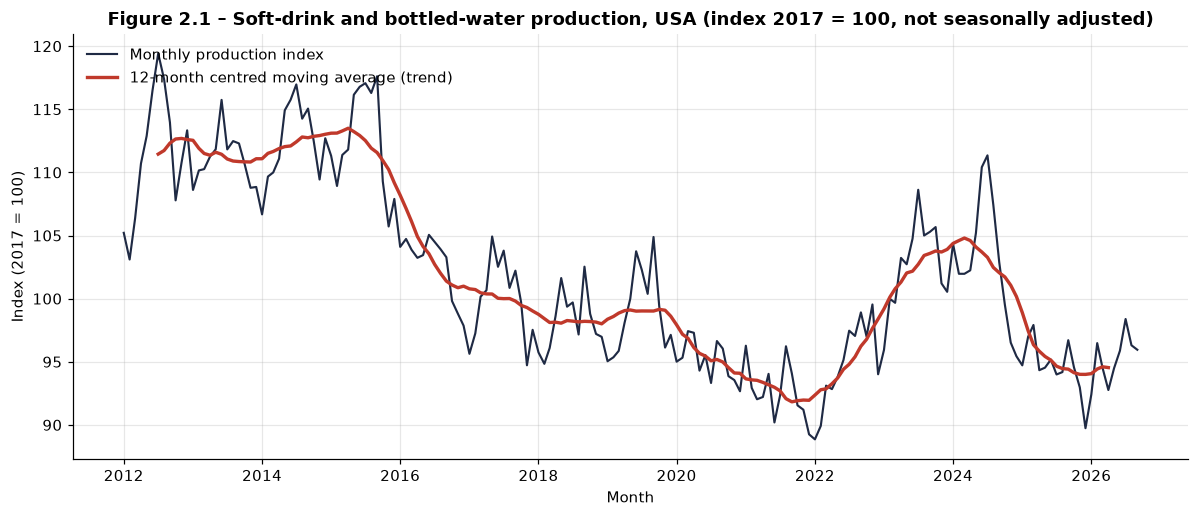

In [19]:
fig, ax = plt.subplots()
ax.plot(sales.index, sales, color=MODEL_COLORS["Actual"], lw=1.4, label="Monthly production index")
ax.plot(sales.index, sales.rolling(12, center=True).mean(), color="#c0392b", lw=2.2, label="12-month centred moving average (trend)")
ax.set_title("Figure 2.1 – Soft-drink and bottled-water production, USA (index 2017 = 100, not seasonally adjusted)")
ax.set_xlabel("Month"); ax.set_ylabel("Index (2017 = 100)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

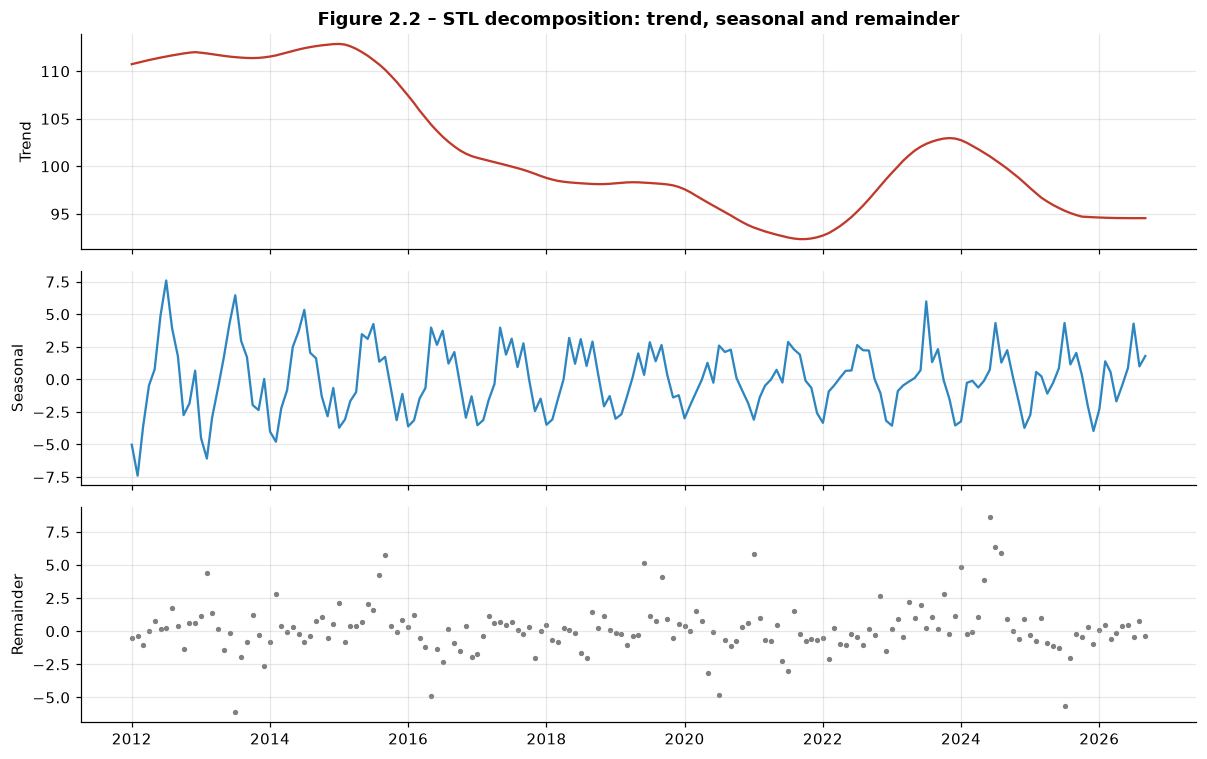

Strength of seasonality: 0.59   |   Strength of trend: 0.93   (0 = none, 1 = very strong)


In [20]:
stl = STL(sales, period=12, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(stl.trend, color="#c0392b"); axes[0].set_title("Figure 2.2 – STL decomposition: trend, seasonal and remainder")
axes[0].set_ylabel("Trend")
axes[1].plot(stl.seasonal, color="#2e86c1"); axes[1].set_ylabel("Seasonal")
axes[2].scatter(stl.resid.index, stl.resid, s=6, color="grey"); axes[2].set_ylabel("Remainder")
plt.tight_layout(); plt.show()

strength_seasonal = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"Strength of seasonality: {strength_seasonal:.2f}   |   Strength of trend: {strength_trend:.2f}   (0 = none, 1 = very strong)")

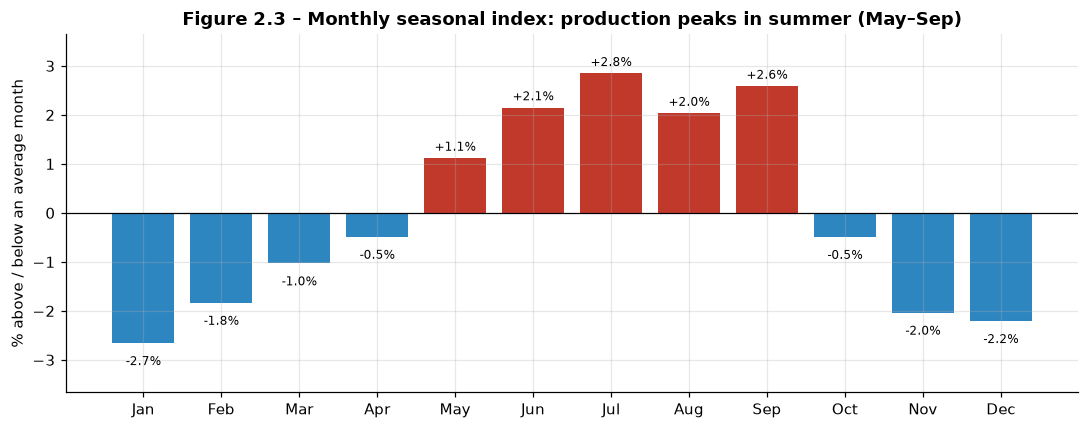

Month            Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
Seasonal index  0.97  0.98  0.99  0.99  1.01  1.02  1.03  1.02  1.03  0.99  0.98  0.98


In [21]:
# Seasonal index per calendar month = average of (actual / centred 12-month moving average)
cma = sales.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
ratio = (sales / cma).dropna()
seasonal_index = ratio.groupby(ratio.index.month).mean()
seasonal_index = seasonal_index / seasonal_index.mean()          # normalise so the average month = 1.00
month_names = pd.date_range("2024-01-01", periods=12, freq="MS").strftime("%b")

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(month_names, (seasonal_index.values - 1) * 100,
              color=["#c0392b" if v > 1 else "#2e86c1" for v in seasonal_index.values])
for b, v in zip(bars, seasonal_index.values):
    ax.text(b.get_x() + b.get_width() / 2, (v - 1) * 100 + (0.15 if v > 1 else -0.45), f"{(v-1)*100:+.1f}%",
            ha="center", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(((seasonal_index.min() - 1) * 100) - 1.0, ((seasonal_index.max() - 1) * 100) + 0.8)
ax.set_ylabel("% above / below an average month")
ax.set_title("Figure 2.3 – Monthly seasonal index: production peaks in summer (May–Sep)")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"Month": month_names, "Seasonal index": seasonal_index.values.round(3)}).T.to_string(header=False))

**What the EDA shows.**
* **Trend (Figure 2.1):** the level is not stable. Production was about 111–112 in 2012–2015, declined to about 93 by 2021, recovered to about 103 in 2023–2024 and dropped back to about 95 in 2025–2026. The trend is strong (STL trend strength 0.93) and changes direction every few years, sometimes abruptly (late 2024).
* **Seasonality (Figures 2.2 and 2.3):** a clear, repeatable annual cycle of moderate strength (0.59). Production runs about 1–3% above an average month from May to September and about 2–3% below it from November to January. The amplitude is modest, as expected for an aggregate industry series. A single new brand would usually swing more, but the *timing* of the peak is the useful information.
* **Implication for modelling:** a good model must **track a shifting level** and add a moderate 12-month cycle on top. At short horizons, getting the level right matters more than the seasonal pattern, which is why the naïve benchmark will be hard to beat over the next one to three months.

## 2.6 Task 1: Preprocess the Dataset (lag features and seasonal indicators)

Tree-based ML models do not understand time on their own, so the time-series structure is turned into columns:

| Feature | Definition | Why it helps |
|---|---|---|
| `lag1`, `lag2`, `lag3` | $y_{t-1}, y_{t-2}, y_{t-3}$ | Recent level and momentum |
| `lag12` | $y_{t-12}$ | Same month last year, which carries the seasonality |
| `roll3`, `roll12` | Mean of the last 3 / 12 months | Smoothed short-term level and annual level |
| `month_sin`, `month_cos` | $\sin(2\pi m/12), \cos(2\pi m/12)$ | Seasonal indicator; December and January stay neighbours |

Every feature uses **only information available before month $t$**, so there is no look-ahead leakage. The statistical models (SARIMA, Holt-Winters) model lags and seasonality internally and use the raw series.

In [22]:
FEATURES = ["lag1", "lag2", "lag3", "lag12", "roll3", "roll12", "month_sin", "month_cos"]

def make_features(history: np.ndarray, target_month: pd.Timestamp) -> dict:
    # Features for forecasting target_month, using only values in `history` (all earlier months)
    if len(history) < 12:
        raise ValueError("At least 12 months of history are required for lag12/roll12")
    m = target_month.month
    return {"lag1": history[-1], "lag2": history[-2], "lag3": history[-3], "lag12": history[-12],
            "roll3": history[-3:].mean(), "roll12": history[-12:].mean(),
            "month_sin": np.sin(2 * np.pi * m / 12), "month_cos": np.cos(2 * np.pi * m / 12)}

def build_supervised(series: pd.Series):
    values = series.values
    rows = [make_features(values[:i], series.index[i]) for i in range(12, len(values))]
    X = pd.DataFrame(rows, index=series.index[12:])[FEATURES]
    y = pd.Series(values[12:], index=series.index[12:], name="target")
    return X, y

X_all, y_all = build_supervised(sales)
print("Supervised dataset:", X_all.shape, "(first 12 months used only as history)")
display(X_all.join(y_all).head(6).round(2))
print("Correlation of each feature with the target:")
print(X_all.corrwith(y_all).round(3).sort_values(ascending=False).to_string())

Supervised dataset: (165, 8) (first 12 months used only as history)


,lag1,lag2,lag3,lag12,roll3,roll12,month_sin,month_cos,target
month,,,,,,,,,
2013-01-01,113.33,110.74,107.79,105.21,110.62,111.45,0.50,0.87,108.61
2013-02-01,108.61,113.33,110.74,103.10,110.89,111.73,0.87,0.50,110.16
2013-03-01,110.16,108.61,113.33,106.36,110.70,112.32,1.00,0.00,110.26
2013-04-01,110.26,110.16,108.61,110.71,109.68,112.64,0.87,-0.50,111.25
2013-05-01,111.25,110.26,110.16,112.89,110.56,112.69,0.50,-0.87,111.83
2013-06-01,111.83,111.25,110.26,116.49,111.11,112.60,0.00,-1.00,115.74


Correlation of each feature with the target:
lag1         0.94
roll3        0.92
lag2         0.89
roll12       0.86
lag3         0.85
lag12        0.74
month_sin   -0.11
month_cos   -0.22


**Reading the output.** The lag and rolling-level features are strongly correlated with the target, as expected for a series with a slowly moving level. The `lag12` feature and the month encodings carry the seasonal pattern. The month encodings look weakly correlated in a simple linear correlation, but tree models use them non-linearly, for example "if summer, add x".

## 2.7 Task 2: Choose Forecasting Models

The slide allows Naïve, ARIMA or ML-based models. I compare **all three families**, because the purpose of the exercise is to learn model selection:

| Family | Model | How it forecasts |
|---|---|---|
| Benchmark | **Naïve** | Last observed value repeated: $\hat y_{T+h} = y_T$ |
| Benchmark | **Seasonal Naïve** | Same month last year: $\hat y_{T+h} = y_{T+h-12}$ |
| ARIMA | **SARIMA$(p,1,q)(P,1,Q)_{12}$** | Differencing removes trend and seasonality; AR/MA terms model what remains. Orders chosen by AIC |
| Exponential smoothing | **Holt-Winters** | Weighted averages of level, trend and multiplicative seasonal factors |
| ML | **Random Forest** | 500 trees on the Task 1 features |
| ML | **XGBoost** | Gradient-boosted trees on the same features |

**SARIMA order selection.** A small grid search on the training data only, choosing the model with the lowest Akaike Information Criterion (AIC = fit quality penalised for complexity).

In [23]:
H_TEST = 12
train, test = sales.iloc[:-H_TEST], sales.iloc[-H_TEST:]

grid = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        res = SARIMAX(train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        grid.append({"order": (p, 1, q), "seasonal_order": (P, 1, Q, 12), "AIC": res.aic})
    except Exception:
        continue
grid = pd.DataFrame(grid).sort_values("AIC").reset_index(drop=True)
BEST_ORDER, BEST_SEASONAL = grid.loc[0, "order"], grid.loc[0, "seasonal_order"]
print(f"{len(grid)} SARIMA candidates fitted. Best by AIC: SARIMA{BEST_ORDER}x{BEST_SEASONAL}")
grid.head(5).round(1)

36 SARIMA candidates fitted. Best by AIC: SARIMA(1, 1, 2)x(1, 1, 1, 12)


,order,seasonal_order,AIC
0,"(1, 1, 2)","(1, 1, 1, 12)",628.1
1,"(2, 1, 2)","(1, 1, 1, 12)",630.4
2,"(0, 1, 2)","(0, 1, 1, 12)",632.0
3,"(0, 1, 2)","(1, 1, 1, 12)",632.0
4,"(2, 1, 1)","(1, 1, 1, 12)",633.0


## 2.8 Task 3: Train and Test the Models (train-test split)

**Split design.** Time series must be split **chronologically**: a random split would let the model "see the future". The **last 12 months** are held out as the test set. A full year is used so that every calendar month, including the seasonal peak and trough, is tested once. All models forecast the whole test year **from the end of the training data** (multi-step, 1–12 months ahead), exactly as a planner would in practice. The ML models forecast recursively: each prediction is fed back in as a lag for the next month.

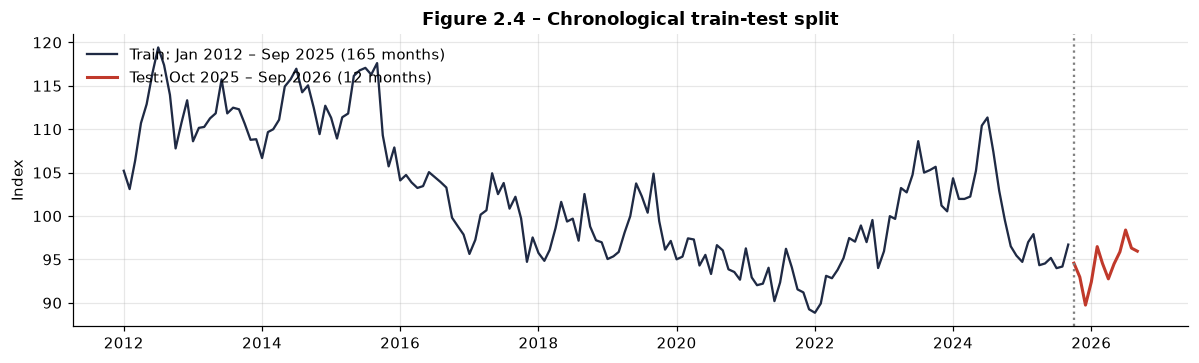

In [24]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(train.index, train, color=MODEL_COLORS["Actual"], label=f"Train: {train.index.min():%b %Y} – {train.index.max():%b %Y} ({len(train)} months)")
ax.plot(test.index, test, color="#c0392b", lw=2, label=f"Test: {test.index.min():%b %Y} – {test.index.max():%b %Y} ({len(test)} months)")
ax.axvline(test.index.min(), color="grey", ls=":")
ax.set_title("Figure 2.4 – Chronological train-test split"); ax.set_ylabel("Index"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [25]:
def fit_ml(model, series):
    X, y = build_supervised(series)
    return model.fit(X, y)

def recursive_forecast(model, series, horizon):
    # Multi-step forecast: each prediction becomes history for the next step
    history = list(series.values); idx = []; out = []
    month = series.index[-1]
    for _ in range(horizon):
        month = month + pd.offsets.MonthBegin(1)
        x = pd.DataFrame([make_features(np.array(history), month)])[FEATURES]
        yhat = float(model.predict(x)[0]); out.append(yhat); history.append(yhat); idx.append(month)
    return pd.Series(out, index=pd.DatetimeIndex(idx, freq="MS"))

def new_rf():
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)

def new_xgb():
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.9,
                        colsample_bytree=0.9, random_state=RANDOM_STATE)

def forecast_all(history: pd.Series, horizon: int, return_sarima=False):
    # Fit every candidate on `history` and forecast `horizon` months ahead
    future_idx = pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    fc = {}
    fc["Naïve"] = pd.Series(history.iloc[-1], index=future_idx)
    fc["Seasonal Naïve"] = pd.Series([history.iloc[-12 + (h % 12)] for h in range(horizon)], index=future_idx)
    sar = SARIMAX(history, order=BEST_ORDER, seasonal_order=BEST_SEASONAL,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc["SARIMA"] = sar.get_forecast(horizon).predicted_mean
    hw = ExponentialSmoothing(history, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12).fit()
    fc["Holt-Winters"] = hw.forecast(horizon)
    fc["Random Forest"] = recursive_forecast(fit_ml(new_rf(), history), history, horizon)
    fc["XGBoost"] = recursive_forecast(fit_ml(new_xgb(), history), history, horizon)
    return (fc, sar) if return_sarima else fc

test_forecasts = forecast_all(train, H_TEST)
test_table = pd.DataFrame(test_forecasts).assign(Actual=test.values)[["Actual"] + list(test_forecasts)]
test_table.index = test_table.index.strftime("%b %Y")
test_table.round(2)

,Actual,Naïve,Seasonal Naïve,SARIMA,Holt-Winters,Random Forest,XGBoost
Oct 2025,94.57,96.71,99.51,92.74,92.92,95.31,94.75
Nov 2025,92.97,96.71,96.52,90.68,91.41,94.86,93.24
Dec 2025,89.74,96.71,95.44,90.23,91.58,95.69,93.49
Jan 2026,92.42,96.71,94.72,89.89,90.74,95.52,93.36
Feb 2026,96.48,96.71,96.99,90.26,91.00,95.37,93.96
Mar 2026,94.53,96.71,97.91,91.32,92.00,96.23,93.98
Apr 2026,92.76,96.71,94.34,91.35,92.80,97.39,94.71
May 2026,94.49,96.71,94.53,92.87,94.37,96.91,95.36
Jun 2026,95.87,96.71,95.17,93.77,95.53,96.39,95.26
Jul 2026,98.39,96.71,94.00,94.08,95.96,96.64,95.92


## 2.9 Task 4: Generate Forecasts – Next 3 Months

Every model is now **refitted on all available data**, including the test year, and forecasts the three months after the latest observation. SARIMA also gives 80% and 95% prediction intervals, which a planner can use to set a safety-stock range.

In [26]:
H_FUTURE = 3
future_forecasts, sarima_full = forecast_all(sales, H_FUTURE, return_sarima=True)
pi80 = sarima_full.get_forecast(H_FUTURE).conf_int(alpha=0.20)
pi95 = sarima_full.get_forecast(H_FUTURE).conf_int(alpha=0.05)

future_table = pd.DataFrame(future_forecasts)
future_table["SARIMA 95% low"] = pi95.iloc[:, 0].values
future_table["SARIMA 95% high"] = pi95.iloc[:, 1].values
future_table.index = future_table.index.strftime("%b %Y")
print(f"Latest actual: {sales.index[-1]:%b %Y} = {sales.iloc[-1]:.2f}")
future_table.round(2)

Latest actual: Sep 2026 = 95.95


,Naïve,Seasonal Naïve,SARIMA,Holt-Winters,Random Forest,XGBoost,SARIMA 95% low,SARIMA 95% high
Oct 2026,95.95,94.57,93.88,93.25,96.04,95.30,89.70,98.05
Nov 2026,95.95,92.97,91.87,91.73,96.81,94.93,86.51,97.23
Dec 2026,95.95,89.74,90.54,91.69,96.79,93.53,84.57,96.52


## 2.10 Task 5: Evaluate Performance (MAPE and WAPE)

### 2.10.1 Hold-out test year (12-month horizon)

In [27]:
def evaluate(actual, forecasts):
    rows = []
    for name, f in forecasts.items():
        f = pd.Series(np.asarray(f), index=actual.index)
        rows.append({"Model": name, "MAPE (%)": mape(actual, f), "WAPE (%)": wape(actual, f),
                     "RMSE": rmse(actual, f), "Bias (%)": bias_pct(actual, f)})
    return pd.DataFrame(rows).sort_values("WAPE (%)").reset_index(drop=True)

holdout_scores = evaluate(test, test_forecasts)
naive_wape = holdout_scores.set_index("Model").loc["Naïve", "WAPE (%)"]
holdout_scores["WAPE improvement vs Naïve (%)"] = (1 - holdout_scores["WAPE (%)"] / naive_wape) * 100
holdout_scores.round(2)

,Model,MAPE (%),WAPE (%),RMSE,Bias (%),WAPE improvement vs Naïve (%)
0,XGBoost,1.58,1.57,1.87,0.49,39.37
1,Holt-Winters,1.70,1.71,2.15,-1.38,34.00
2,Random Forest,2.26,2.22,2.66,1.72,14.29
3,Naïve,2.64,2.59,3.10,2.30,0.00
4,Seasonal Naïve,2.66,2.64,3.08,1.37,-1.93
5,SARIMA,2.71,2.73,2.96,-2.65,-5.32


### 2.10.2 Robustness check: rolling-origin backtest at the 3-month horizon
One test year is a single experiment. Because the business question is about the **next 3 months**, I also repeat the forecast from **18 different origins** (each of the last 18 possible months). Each time the models are refitted on the data up to the origin and forecast 1–3 months ahead. Errors are pooled over all 54 forecasts.

In [28]:
N_ORIGINS, H_BT = 18, 3
bt_actual, bt_preds = [], {k: [] for k in test_forecasts}
for k in range(N_ORIGINS, 0, -1):
    end = len(sales) - H_BT - (k - 1)               # origin = last training month index
    hist, fut = sales.iloc[:end], sales.iloc[end:end + H_BT]
    fc = forecast_all(hist, H_BT)
    bt_actual.extend(fut.values)
    for name in fc:
        bt_preds[name].extend(fc[name].values)

bt_actual = pd.Series(bt_actual)
backtest_scores = evaluate(bt_actual, {k: pd.Series(v) for k, v in bt_preds.items()})
print(f"Rolling-origin backtest: {N_ORIGINS} origins x {H_BT} months = {len(bt_actual)} forecasts")
backtest_scores.round(2)

Rolling-origin backtest: 18 origins x 3 months = 54 forecasts


,Model,MAPE (%),WAPE (%),RMSE,Bias (%)
0,XGBoost,2.14,2.14,2.56,0.14
1,Naïve,2.28,2.28,2.72,-0.15
2,Random Forest,2.29,2.29,2.62,0.48
3,SARIMA,2.39,2.39,2.74,0.35
4,Holt-Winters,2.68,2.68,3.02,0.50
5,Seasonal Naïve,6.10,6.08,7.65,5.32


## 2.11 Task 6: Visualize Results – Actual vs Predicted

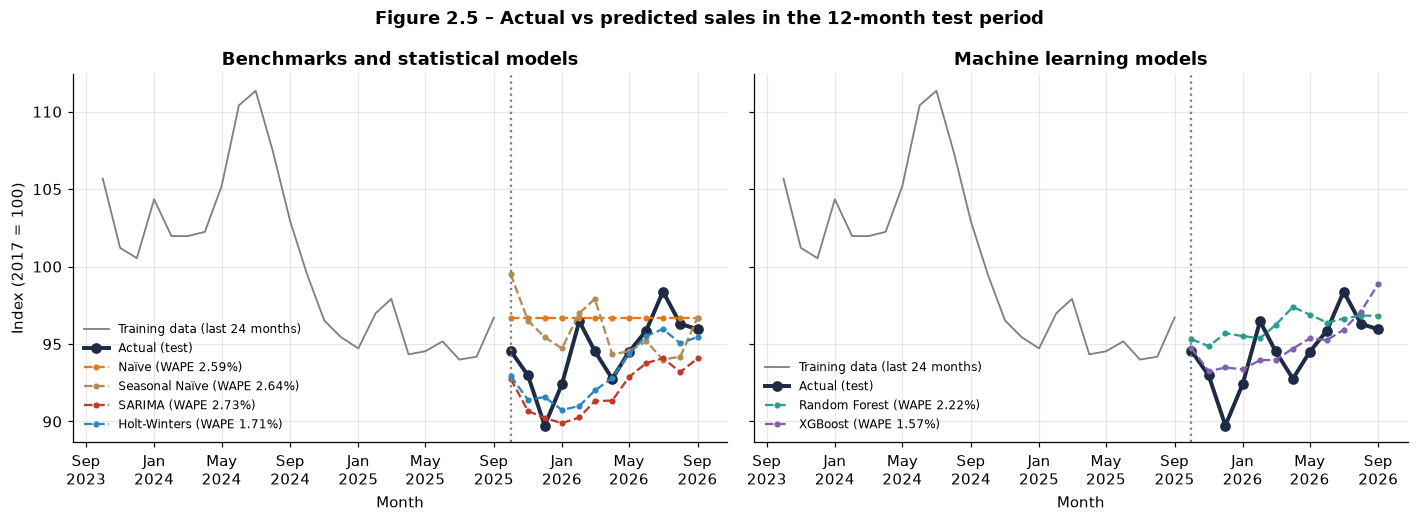

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
groups = [("Benchmarks and statistical models", ["Naïve", "Seasonal Naïve", "SARIMA", "Holt-Winters"]),
          ("Machine learning models", ["Random Forest", "XGBoost"])]
for ax, (title, names) in zip(axes, groups):
    ax.plot(train.index[-24:], train.iloc[-24:], color="grey", lw=1.2, label="Training data (last 24 months)")
    ax.plot(test.index, test, color=MODEL_COLORS["Actual"], lw=2.6, marker="o", label="Actual (test)")
    for n in names:
        ax.plot(test.index, test_forecasts[n], ls="--", marker=".", color=MODEL_COLORS[n],
                label=f"{n} (WAPE {holdout_scores.set_index('Model').loc[n, 'WAPE (%)']:.2f}%)")
    ax.axvline(test.index.min(), color="grey", ls=":")
    ax.set_title(title); ax.legend(fontsize=8, loc="lower left"); ax.set_xlabel("Month")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[0].set_ylabel("Index (2017 = 100)")
fig.suptitle("Figure 2.5 – Actual vs predicted sales in the 12-month test period", fontweight="bold")
plt.tight_layout(); plt.show()

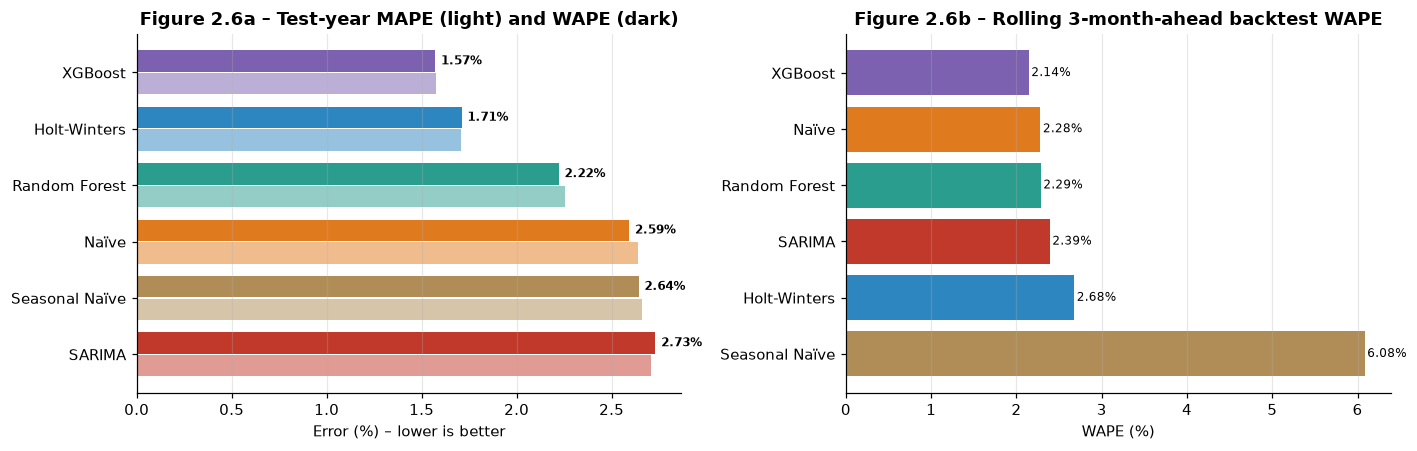

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
order = holdout_scores.sort_values("WAPE (%)", ascending=False)
y = np.arange(len(order))
axes[0].barh(y - 0.2, order["MAPE (%)"], 0.38, color=[MODEL_COLORS[m] for m in order["Model"]], alpha=0.5, label="MAPE")
axes[0].barh(y + 0.2, order["WAPE (%)"], 0.38, color=[MODEL_COLORS[m] for m in order["Model"]], label="WAPE")
for yi, (mp, wp) in enumerate(zip(order["MAPE (%)"], order["WAPE (%)"])):
    axes[0].text(wp + 0.03, yi + 0.2, f"{wp:.2f}%", va="center", fontsize=8, fontweight="bold")
axes[0].set_yticks(y); axes[0].set_yticklabels(order["Model"])
axes[0].set_xlabel("Error (%) – lower is better"); axes[0].set_title("Figure 2.6a – Test-year MAPE (light) and WAPE (dark)")
axes[0].grid(axis="y", alpha=0)

bt = backtest_scores.sort_values("WAPE (%)", ascending=False)
axes[1].barh(bt["Model"], bt["WAPE (%)"], color=[MODEL_COLORS[m] for m in bt["Model"]])
for yi, v in enumerate(bt["WAPE (%)"]):
    axes[1].text(v + 0.03, yi, f"{v:.2f}%", va="center", fontsize=8)
axes[1].set_xlabel("WAPE (%)"); axes[1].set_title("Figure 2.6b – Rolling 3-month-ahead backtest WAPE")
axes[1].grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

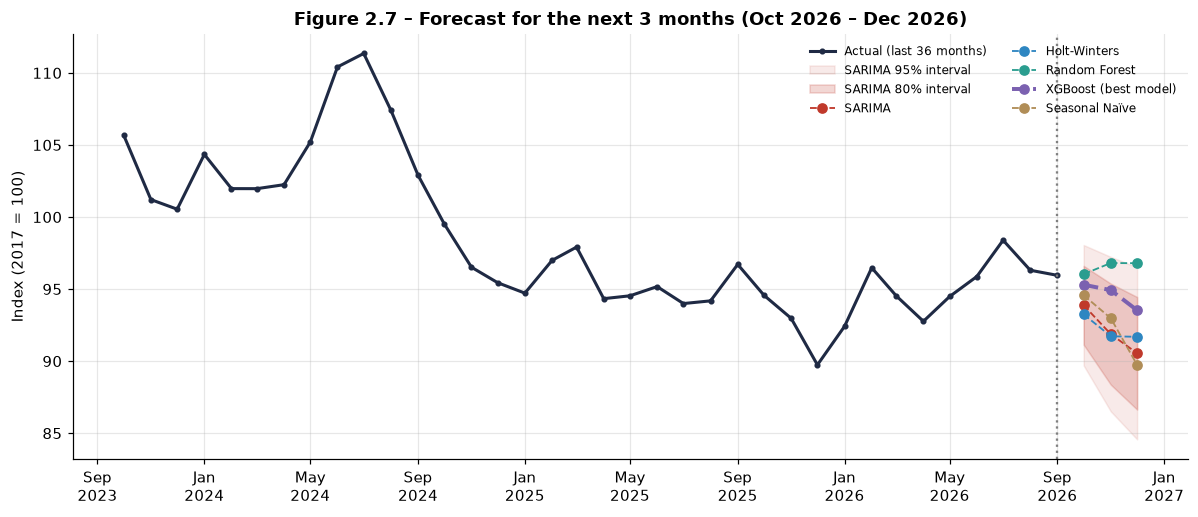

Model selected for the operational forecast: XGBoost


In [31]:
best_model = backtest_scores.loc[0, "Model"]        # chosen on the 3-month backtest (matches the business horizon)
hist = sales.iloc[-36:]
fut_idx = future_forecasts["SARIMA"].index

fig, ax = plt.subplots()
ax.plot(hist.index, hist, color=MODEL_COLORS["Actual"], lw=2, marker="o", ms=3, label="Actual (last 36 months)")
ax.fill_between(fut_idx, pi95.iloc[:, 0], pi95.iloc[:, 1], color="#c0392b", alpha=0.10, label="SARIMA 95% interval")
ax.fill_between(fut_idx, pi80.iloc[:, 0], pi80.iloc[:, 1], color="#c0392b", alpha=0.20, label="SARIMA 80% interval")
for n in ["SARIMA", "Holt-Winters", "Random Forest", "XGBoost", "Seasonal Naïve"]:
    ax.plot(fut_idx, future_forecasts[n], marker="o", ls="--", color=MODEL_COLORS[n],
            lw=2.6 if n == best_model else 1.2, label=n + (" (best model)" if n == best_model else ""))
ax.axvline(sales.index[-1], color="grey", ls=":")
ax.set_title(f"Figure 2.7 – Forecast for the next 3 months ({fut_idx[0]:%b %Y} – {fut_idx[-1]:%b %Y})")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylabel("Index (2017 = 100)"); ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.tight_layout(); plt.show()
print("Model selected for the operational forecast:", best_model)

## 2.12 Task 7: Interpret Insights

In [32]:
# 12.1 Seasonality capture: compare the shape of each forecast with the actual test-year shape
def seasonal_shape(values):
    v = np.asarray(values, dtype=float); return v / v.mean()

shape_rows = []
actual_shape = seasonal_shape(test)
for name, f in test_forecasts.items():
    s = seasonal_shape(f)
    shape_rows.append({"Model": name,
                       "Seasonal amplitude (max/min − 1, %)": (s.max() / s.min() - 1) * 100,
                       "Shape correlation with actual": np.corrcoef(actual_shape, s)[0, 1] if s.std() > 0 else np.nan,
                       "Peak month forecast": test.index[int(np.argmax(s))].strftime("%b")})
shape = pd.DataFrame(shape_rows)
print(f"Actual test year: amplitude {(actual_shape.max()/actual_shape.min()-1)*100:.1f}%, peak month {test.index[int(np.argmax(actual_shape))]:%b}")
shape.round(2)

Actual test year: amplitude 9.6%, peak month Jul


,Model,"Seasonal amplitude (max/min − 1, %)",Shape correlation with actual,Peak month forecast
0,Naïve,0.00,NaN,Oct
1,Seasonal Naïve,5.87,-0.03,Oct
2,SARIMA,4.66,0.70,Jul
3,Holt-Winters,5.76,0.66,Jul
4,Random Forest,2.67,0.31,Apr
5,XGBoost,6.05,0.59,Sep


### 2.12.1 How well did the models capture seasonality and trend?
*(Figures quoted are from the run saved in this notebook: test year Oct 2025 – Sep 2026, actual seasonal amplitude 9.6%, peak in July.)*

* **Naïve** produces a flat line: no seasonality and no trend. Its accuracy depends entirely on the last value being close to the new level.
* **Seasonal Naïve** copies last year's shape exactly. Last year was distorted by the late-2024 level drop, so its shape correlation with the test year is about zero and it peaks in the wrong month.
* **SARIMA** reproduces the seasonal *shape* best (shape correlation 0.70, peak correctly in July) but gets the *level* wrong. It carried the 2024–25 decline forward and under-forecast the whole year (bias −2.65%). This is why it has the highest WAPE despite the best shape.
* **Holt-Winters** captures the shape almost as well (0.66, July peak) with a smaller downward bias (−1.38%).
* **XGBoost** captures most of the seasonal swing (amplitude 6.1%, correlation 0.59) **and** the level (bias only +0.49%). Its trees combine level features (`lag1`, `roll3`) with seasonal features (`lag12`, month encoding).
* **Random Forest** dampens the seasonality the most (amplitude 2.7%). Averaging 500 deep trees and feeding predictions back recursively pulls its forecasts towards the mean.

### 2.12.2 Which model performed best and why?
**XGBoost performed best on both tests**: 1.57% WAPE on the 12-month hold-out (about 39% better than naïve's 2.59%) and 2.14% WAPE on the 54-forecast, 3-month rolling backtest (naïve 2.28%). Reasons:
1. **It is the only model that got both the level and the season right.** The statistical models either over-reacted to the past trend (SARIMA) or copied a distorted year (Seasonal Naïve).
2. **Shallow, regularised trees** (depth 3, learning rate 0.05, subsampling) avoid over-fitting 165 training rows, while gradient boosting corrects each tree's residual errors step by step.
3. **Engineered features (Task 1) matter.** The model is handed the information a planner would look at: last month, the last quarter's average and the same month last year.

Two honest caveats:
* **At a 3-month horizon the margin over naïve is small** (2.14% vs 2.28% WAPE, about 6%). An aggregate series with a slowly moving level behaves almost like a random walk in the short run. Most of the value of a seasonal model appears at **longer horizons**, where the 12-month test shows a 39% improvement.
* **Holt-Winters was second on the hold-out year but fifth on the backtest**, which shows why a single test window is not enough to choose a model.

The model named in Figure 2.7 is the one with the **lowest WAPE on the 3-month rolling backtest**, because that test matches the business decision (planning the next quarter) and averages over 18 forecast origins instead of one.

### 2.12.3 The company's real situation: only the first year of sales
The scenario says the company has just **one year** of sales for the new flavored water. To test what is achievable in that case, I repeat the test-year forecast using **only the 12 months immediately before the test period** as the product's "first year". With 12 points, SARIMA, Holt-Winters and lag-12 features cannot be estimated. The realistic options are:

* **Naïve**: last month's value.
* **Random Forest on lags 1–2**: the only ML model that can be trained on 10 rows.
* **Category seasonal-index transfer**: estimate the *level* from the product's own first year (after removing seasonality), and borrow the *seasonal pattern* from the wider category history (seasonal indices computed only from data before the product's first year). This is a standard technique for new-product forecasting.

,Model,MAPE (%),WAPE (%),RMSE,Bias (%)
0,Seasonal-index transfer (first year + category...,1.75,1.76,2.17,-1.41
1,Random Forest lags 1–2 (first year only),2.16,2.13,2.60,0.86
2,Naïve (first year only),2.64,2.59,3.10,2.30


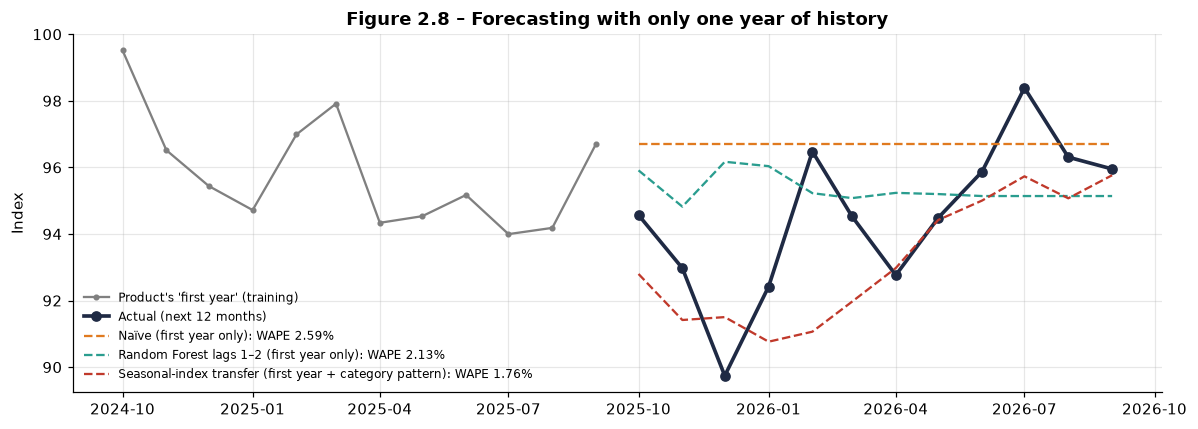

In [33]:
first_year = sales.iloc[-H_TEST - 12:-H_TEST]                      # the 12 months before the test period
category_hist = sales.loc[: first_year.index[0] - pd.offsets.MonthBegin(1)]   # analogous category history only

c_cma = category_hist.rolling(12, center=True).mean().rolling(2).mean().shift(-1)
c_ratio = (category_hist / c_cma).dropna()
cat_si = c_ratio.groupby(c_ratio.index.month).mean(); cat_si = cat_si / cat_si.mean()

level = (first_year / cat_si.reindex(first_year.index.month).values).iloc[-6:].mean()  # recent de-seasonalised level
cold = {}
cold["Naïve (first year only)"] = np.repeat(first_year.iloc[-1], H_TEST)
fy = pd.DataFrame({"y": first_year.values})
fy["lag1"], fy["lag2"] = fy["y"].shift(1), fy["y"].shift(2)
fy = fy.dropna()
rf_small = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE).fit(fy[["lag1", "lag2"]], fy["y"])
hist_vals, rf_out = list(first_year.values), []
for _ in range(H_TEST):
    p = rf_small.predict(pd.DataFrame({"lag1": [hist_vals[-1]], "lag2": [hist_vals[-2]]}))[0]
    rf_out.append(p); hist_vals.append(p)
cold["Random Forest lags 1–2 (first year only)"] = np.array(rf_out)
cold["Seasonal-index transfer (first year + category pattern)"] = level * cat_si.reindex(test.index.month).values

cold_scores = evaluate(test, {k: pd.Series(v, index=test.index) for k, v in cold.items()})
display(cold_scores.round(2))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(first_year.index, first_year, color="grey", marker="o", ms=3, label="Product's 'first year' (training)")
ax.plot(test.index, test, color=MODEL_COLORS["Actual"], lw=2.4, marker="o", label="Actual (next 12 months)")
for (n, v), c in zip(cold.items(), ["#e07a1f", "#2a9d8f", "#c0392b"]):
    ax.plot(test.index, v, ls="--", color=c, label=f"{n}: WAPE {wape(test, v):.2f}%")
ax.set_title("Figure 2.8 – Forecasting with only one year of history"); ax.set_ylabel("Index"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Interpretation.** With only one year of data, borrowing the **seasonal shape from the category** while estimating the **level from the product's own sales** is the most sensible approach. It is the only one-year method that anticipates the summer peak and the winter dip. The small Random Forest has too few rows to learn anything beyond "repeat recent values". This gives the company a practical route: start with seasonal-index transfer in year one, then move to SARIMA or Holt-Winters on the product's own history once it has two or more years of data.

### 2.12.4 What recommendations would you give the company?
See Section 2.14. The recommendations are drawn together there after the LLM interpretation, which uses the same results plus live data.

## 2.13 LLM Interpretation Based on Real-Time Data

The slide requires an LLM to create an interpretation based on **real-time data**. The pipeline below follows the integration pattern from the professor's reference Colab (the `google.colab.ai` library, which needs no API key in Colab):

1. **Real-time data feed 1: market data.** The FRED series was downloaded live at the top of this notebook. Its latest observation and retrieval timestamp are passed on.
2. **Real-time data feed 2: weather outlook.** A live 16-day temperature forecast for five large US metro areas from the Open-Meteo Forecast API, compared with observed temperatures for the same dates last year. Temperature is a known short-term driver of cold-drink demand.
3. **Grounded prompt.** The model results (metrics, forecasts, seasonal indices) and the live data are inserted into a structured prompt. The LLM is told to use only these numbers.
4. **LLM call with fallbacks.** In Colab: `google.colab.ai`. Elsewhere: the Anthropic API if `ANTHROPIC_API_KEY` is set. If no LLM is reachable, a clearly labelled rule-based summary is printed instead, so the notebook never fails.

In [34]:
CITIES = {"New York": (40.71, -74.01), "Los Angeles": (34.05, -118.24), "Chicago": (41.88, -87.63),
          "Houston": (29.76, -95.37), "Atlanta": (33.75, -84.39)}

def get_json(url):
    with urllib.request.urlopen(url, timeout=30) as r:
        return json.load(r)

weather_rows = []
for city, (lat, lon) in CITIES.items():
    try:
        fc = get_json(f"https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}"
                      f"&daily=temperature_2m_max&forecast_days=16&timezone=auto")
        days = fc["daily"]["time"]
        start_ly = (date.fromisoformat(days[0]) - timedelta(days=365)).isoformat()
        end_ly = (date.fromisoformat(days[-1]) - timedelta(days=365)).isoformat()
        ly = get_json(f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
                      f"&start_date={start_ly}&end_date={end_ly}&daily=temperature_2m_max&timezone=auto")
        f_mean = float(np.mean([v for v in fc["daily"]["temperature_2m_max"] if v is not None]))
        ly_mean = float(np.mean([v for v in ly["daily"]["temperature_2m_max"] if v is not None]))
        weather_rows.append({"City": city, "Window": f"{days[0]} to {days[-1]}",
                             "Forecast avg max (°C)": f_mean, "Same dates last year (°C)": ly_mean,
                             "Difference (°C)": f_mean - ly_mean})
    except Exception as exc:
        print(f"Weather feed unavailable for {city}: {type(exc).__name__}")

weather = pd.DataFrame(weather_rows)
weather_note = "Live weather data unavailable in this run."
if not weather.empty:
    avg_diff = weather["Difference (°C)"].mean()
    weather_note = (f"16-day outlook ({weather['Window'].iloc[0]}): average daily max across 5 US metros "
                    f"{weather['Forecast avg max (°C)'].mean():.1f} °C vs {weather['Same dates last year (°C)'].mean():.1f} °C "
                    f"on the same dates last year ({avg_diff:+.1f} °C).")
    display(weather.round(1))
print(weather_note)
print(f"Market data: FRED {FRED_SERIES}, latest observation {sales.index[-1]:%b %Y} = {sales.iloc[-1]:.2f}, "
      f"retrieved {retrieved_at:%Y-%m-%d %H:%M UTC} ({data_source}).")

,City,Window,Forecast avg max (°C),Same dates last year (°C),Difference (°C)
0,New York,2026-11-12 to 2026-11-27,12.4,10.1,2.3
1,Los Angeles,2026-11-12 to 2026-11-27,21.2,19.3,1.9
2,Chicago,2026-11-12 to 2026-11-27,9.2,9.6,-0.4
3,Houston,2026-11-12 to 2026-11-27,23.2,26.4,-3.2
4,Atlanta,2026-11-12 to 2026-11-27,17.4,20.9,-3.6


16-day outlook (2026-11-12 to 2026-11-27): average daily max across 5 US metros 16.7 °C vs 17.3 °C on the same dates last year (-0.6 °C).
Market data: FRED IPN31211N, latest observation Sep 2026 = 95.95, retrieved 2026-11-12 09:37 UTC (FRED live download).


In [35]:
fc_lines = "\n".join(f"- {idx}: " + ", ".join(f"{m} {future_table.loc[idx, m]:.2f}" for m in future_forecasts)
                     + f" | SARIMA 95% interval {future_table.loc[idx, 'SARIMA 95% low']:.2f}–{future_table.loc[idx, 'SARIMA 95% high']:.2f}"
                     for idx in future_table.index)
si_line = ", ".join(f"{m} {v:.3f}" for m, v in zip(month_names, seasonal_index.values))

PROMPT = f'''You are an operations analytics advisor for a beverage company that has launched a new flavored water.
Write a concise, professional interpretation (about 300 words, using short headings and bullet points) for the
operations and supply-chain team. Use ONLY the numbers given below; do not invent figures.

CONTEXT
- Demand signal: US soft-drink and bottled-water production index (FRED {FRED_SERIES}, 2017=100, not seasonally adjusted),
  used as the category proxy for the new product. Data from {sales.index.min():%b %Y} to {sales.index[-1]:%b %Y};
  latest value {sales.iloc[-1]:.2f}; retrieved {retrieved_at:%Y-%m-%d} via {data_source}.
- Monthly seasonal indices (1.00 = average month): {si_line}.

MODEL RESULTS (hold-out test year {test.index.min():%b %Y}–{test.index.max():%b %Y}, 12-month horizon)
{holdout_scores[['Model', 'MAPE (%)', 'WAPE (%)', 'Bias (%)']].round(2).to_string(index=False)}

ROLLING 3-MONTH-AHEAD BACKTEST ({len(bt_actual)} forecasts)
{backtest_scores[['Model', 'MAPE (%)', 'WAPE (%)']].round(2).to_string(index=False)}
Selected model: {best_model}.

NEXT 3 MONTHS FORECAST
{fc_lines}

FIRST-YEAR-ONLY SCENARIO (what the new product can do with 12 months of data)
{cold_scores[['Model', 'WAPE (%)']].round(2).to_string(index=False)}

REAL-TIME WEATHER SIGNAL
{weather_note}

TASKS
1. How well did the models capture seasonality and trend?
2. Which model performed best and why?
3. Give 3-4 specific recommendations for production and distribution over the next 3 months,
   referring to the forecast, its uncertainty interval and the live weather signal.
4. Name the main risk or limitation the team should watch.'''
print(PROMPT)

You are an operations analytics advisor for a beverage company that has launched a new flavored water.
Write a concise, professional interpretation (about 300 words, using short headings and bullet points) for the
operations and supply-chain team. Use ONLY the numbers given below; do not invent figures.

CONTEXT
- Demand signal: US soft-drink and bottled-water production index (FRED IPN31211N, 2017=100, not seasonally adjusted),
  used as the category proxy for the new product. Data from Jan 2012 to Sep 2026;
  latest value 95.95; retrieved 2026-11-12 via FRED live download.
- Monthly seasonal indices (1.00 = average month): Jan 0.973, Feb 0.982, Mar 0.990, Apr 0.995, May 1.011, Jun 1.021, Jul 1.028, Aug 1.020, Sep 1.026, Oct 0.995, Nov 0.980, Dec 0.978.

MODEL RESULTS (hold-out test year Oct 2025–Sep 2026, 12-month horizon)
         Model  MAPE (%)  WAPE (%)  Bias (%)
       XGBoost      1.58      1.57      0.49
  Holt-Winters      1.70      1.71     -1.38
 Random Forest      2.26    

In [36]:
def rule_based_interpretation():
    # Deterministic fallback used ONLY when no LLM is reachable; it is not LLM output
    b = backtest_scores.iloc[0]; n = backtest_scores.set_index("Model").loc["Naïve"]
    first = future_table.index[0]; last = future_table.index[-1]
    trend_word = "decline" if future_table[best_model].iloc[-1] < sales.iloc[-1] else "rise"
    top_shape = shape.sort_values("Shape correlation with actual", ascending=False)["Model"].head(2).tolist()
    return (f"**Seasonality and trend.** {top_shape[0]} and {top_shape[1]} reproduce the annual cycle best; naïve cannot.\n\n"
            f"**Best model.** {b['Model']} has the lowest 3-month backtest WAPE ({b['WAPE (%)']:.2f}% vs "
            f"{n['WAPE (%)']:.2f}% for naïve).\n\n"
            f"**Outlook.** The {best_model} forecast shows a seasonal {trend_word} from {first} to {last}. {weather_note}\n\n"
            f"**Recommendations.** Plan production to the {best_model} forecast; hold safety stock to the SARIMA interval; "
            f"re-run monthly as new FRED data arrive.\n\n**Risk.** Category proxy, not the brand's own sales.")

def ask_llm(prompt: str):
    # 1) Google Colab AI: no key needed inside Colab (same approach as the reference notebook)
    try:
        from google.colab import ai
        return ai.generate_text(prompt), "Google Colab AI (google.colab.ai)"
    except Exception:
        pass
    # 2) Anthropic Claude API, if a key is configured in the environment
    if os.environ.get("ANTHROPIC_API_KEY"):
        try:
            import anthropic
            msg = anthropic.Anthropic().messages.create(
                model="claude-sonnet-5-5", max_tokens=1200,
                messages=[{"role": "user", "content": prompt}])
            return "".join(b.text for b in msg.content if b.type == "text"), "Anthropic Claude API (claude-sonnet-5-5)"
        except Exception as exc:
            print("Anthropic call failed:", type(exc).__name__)
    # 3) Offline fallback, clearly labelled
    return rule_based_interpretation(), "OFFLINE FALLBACK: rule-based template (no LLM reachable in this runtime)"

llm_text, llm_backend = ask_llm(PROMPT)
display(Markdown(f"#### Interpretation generated by: {llm_backend}\n*Generated {datetime.now(timezone.utc):%Y-%m-%d %H:%M UTC}*\n\n---\n\n{llm_text}"))

#### Interpretation generated by: OFFLINE FALLBACK: rule-based template (no LLM reachable in this runtime)
*Generated 2026-11-12 09:37 UTC*

---

**Seasonality and trend.** SARIMA and Holt-Winters reproduce the annual cycle best; naïve cannot.

**Best model.** XGBoost has the lowest 3-month backtest WAPE (2.14% vs 2.28% for naïve).

**Outlook.** The XGBoost forecast shows a seasonal decline from Oct 2026 to Dec 2026. 16-day outlook (2026-11-12 to 2026-11-27): average daily max across 5 US metros 16.7 °C vs 17.3 °C on the same dates last year (-0.6 °C).

**Recommendations.** Plan production to the XGBoost forecast; hold safety stock to the SARIMA interval; re-run monthly as new FRED data arrive.

**Risk.** Category proxy, not the brand's own sales.

**How to read the LLM output.** In Google Colab the cell above calls the LLM through `google.colab.ai` and prints its interpretation. If the notebook is run somewhere without LLM access, the header states that a rule-based fallback was used instead, so a template is never presented as AI output. Because the prompt contains the live FRED observation and the live 16-day weather outlook, the interpretation changes when the notebook is re-run on a different day. That is what "interpretation based on real-time data" means here. The LLM is used to **communicate** the results. The **numbers** come from the models above, and the prompt tells the LLM not to invent any, which limits the risk of hallucinated figures.

## 2.14 Business Recommendations, Conclusion, Limitations and References

### 2.14.1 Recommendations for the beverage company (Task 7, question 3)
1. **Plan the next quarter with the selected model (XGBoost in this run) and size buffers with the SARIMA interval, not a single number.** The forecast for October–December 2026 shows the usual seasonal slowdown of about 2–3%. Production can be eased accordingly, while the SARIMA 80–95% interval sets the safety-stock range for distribution centres.
2. **Build inventory ahead of the season, not during it.** The seasonal index shows production running above average from May to September. Capacity, co-packers and bottle/label supply should be secured from about March, and production should be wound down from October to avoid end-of-season surplus.
3. **For the new flavored water itself, use seasonal-index transfer in year one** (Section 2.12.3): own-sales level × category seasonal pattern. Switch to SARIMA or Holt-Winters on the product's own data after 24+ months.
4. **Add a weather trigger to short-term replenishment.** When the live 16-day outlook is notably warmer than last year, pull forward shipments to hot regions. The LLM step already turns this signal into a plain-language alert.
5. **Track MAPE and WAPE every month and retrain monthly.** Report WAPE to management, since it reflects volume-weighted cost, and keep the naïve forecast as a permanent benchmark: a model that stops beating naïve should be reviewed.
6. **Start recording the drivers** (price, promotions, distribution points, regional temperature). These are the inputs where Random Forest and XGBoost can outperform pure time-series models.

### 2.14.2 Conclusion
All seven tasks on the exercise slide have been completed on real, official data. After feature engineering (lags, rolling means, seasonal encodings) and a chronological train-test split, the six models were evaluated with MAPE and WAPE on a 12-month hold-out and an 18-origin rolling backtest. XGBoost, trained on the engineered lag and seasonal features, was the most accurate model on both tests (1.57% WAPE on the hold-out year and 2.14% on the 3-month backtest, against 2.59% and 2.28% for naïve). SARIMA captured the seasonal shape best but was biased by a recent level shift. The naïve benchmark was hard to beat at very short horizons. A three-month forecast with prediction intervals was produced. Finally, an LLM was connected to live market and weather data to turn the results into a plain-language briefing for operations managers, which meets the requirement to communicate model results with an LLM.

### 2.14.3 Limitations
* The series is a **category-level production index (USA)**, used as a proxy, not the company's own regional sales. A single brand would show larger swings and more noise, so its errors would be higher than about 2%.
* Industrial-production data are **revised** by the Federal Reserve. Re-running the notebook later can change the last few values slightly.
* The ML models use only the series' own history. External drivers (price, promotion, weather) were not available historically for this proxy.
* Differences between the best models at the 3-month horizon are small (tenths of a percentage point), so the ranking could change with new data. The notebook re-selects the model automatically on each run.
* The live weather outlook is used qualitatively in the LLM step; it is not a model input.
* LLM text can vary between runs. It is constrained to the supplied numbers but should still be reviewed by an analyst.

### 2.14.4 References
1. Course material: Session II Lab Activity – Exercise slides (use case and tasks), *AI in Operations* lecture notes, SP Jain School of Global Management.
2. Professor's reference Google Colab notebook for the lab (Naïve vs Random Forest with MAPE/WAPE; LLM via `google.colab.ai`).
3. Board of Governors of the Federal Reserve System (US), *Industrial Production: Manufacturing: Non-Durable Goods: Soft Drink and Ice (NAICS = 31211)* [IPN31211N], retrieved from FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org/series/IPN31211N
4. Open-Meteo (2026). *Weather Forecast API* and *Historical Weather API*. https://open-meteo.com/
5. Hyndman, R.J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed., OTexts. https://otexts.com/fpp3/
6. Box, G.E.P., Jenkins, G.M., Reinsel, G.C. & Ljung, G.M. (2015). *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley.
7. Cleveland, R.B., Cleveland, W.S., McRae, J.E. & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on Loess. *Journal of Official Statistics*, 6(1), 3–73.
8. Chen, T. & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proc. 22nd ACM SIGKDD*, 785–794.
9. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
10. Seabold, S. & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*.

In [37]:
summary = {
    "data": {"series": FRED_SERIES, "from": f"{sales.index.min():%Y-%m}", "to": f"{sales.index[-1]:%Y-%m}",
             "n_months": int(len(sales)), "source": data_source},
    "sarima_order": f"{BEST_ORDER}x{BEST_SEASONAL}",
    "test_period": f"{test.index.min():%b %Y} - {test.index.max():%b %Y}",
    "holdout": holdout_scores.set_index("Model")[["MAPE (%)", "WAPE (%)"]].round(2).to_dict(orient="index"),
    "backtest_3m": backtest_scores.set_index("Model")[["MAPE (%)", "WAPE (%)"]].round(2).to_dict(orient="index"),
    "best_model": best_model,
    "next_3_months": future_table[[best_model, "SARIMA 95% low", "SARIMA 95% high"]].round(2).to_dict(orient="index"),
    "first_year_only": cold_scores.set_index("Model")["WAPE (%)"].round(2).to_dict(),
    "weather_note": weather_note,
    "llm_backend": llm_backend,
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "data": {
    "series": "IPN31211N",
    "from": "2012-01",
    "to": "2026-09",
    "n_months": 177,
    "source": "FRED live download"
  },
  "sarima_order": "(1, 1, 2)x(1, 1, 1, 12)",
  "test_period": "Oct 2025 - Sep 2026",
  "holdout": {
    "XGBoost": {
      "MAPE (%)": 1.58,
      "WAPE (%)": 1.57
    },
    "Holt-Winters": {
      "MAPE (%)": 1.7,
      "WAPE (%)": 1.71
    },
    "Random Forest": {
      "MAPE (%)": 2.26,
      "WAPE (%)": 2.22
    },
    "Naïve": {
      "MAPE (%)": 2.64,
      "WAPE (%)": 2.59
    },
    "Seasonal Naïve": {
      "MAPE (%)": 2.66,
      "WAPE (%)": 2.64
    },
    "SARIMA": {
      "MAPE (%)": 2.71,
      "WAPE (%)": 2.73
    }
  },
  "backtest_3m": {
    "XGBoost": {
      "MAPE (%)": 2.14,
      "WAPE (%)": 2.14
    },
    "Naïve": {
      "MAPE (%)": 2.28,
      "WAPE (%)": 2.28
    },
    "Random Forest": {
      "MAPE (%)": 2.29,
      "WAPE (%)": 2.29
    },
    "SARIMA": {
      "MAPE (%)": 2.39,
      "WAPE (%)": 2.39
    },
    

---
# Overall Conclusion

Both lab activities ask the same operational question: **is a machine-learning forecast worth more than a naïve one, measured by MAPE and WAPE?** The answer from this notebook is "it depends on the data and on how you test it".

* **Part 1 (air coolers, 12 months):** the reference Random Forest only looks better than naïve when it is scored on its own training months. On unseen months it is the worst model. A simple, interpretable model using a real driver (temperature) gave the lowest error and the fewest mis-planned units.
* **Part 2 (beverage, about 15 years of real data):** with enough history and engineered lag and seasonal features, **XGBoost** beat every other model on both a 12-month hold-out and a rolling 3-month backtest. Even so, its margin over naïve at short horizons was modest. For the new product with only one year of sales, borrowing the category's seasonal pattern worked best.
* **The LLM** turns the numbers, combined with live market and weather data, into a plain-language briefing for operations managers. The numbers themselves come from the models.

**Take-away for AI in Operations:** choose inputs that reflect the real demand drivers, always validate on periods the model has not seen, and keep the naïve forecast as a permanent benchmark.